# Nashville City Cemetery, 1846–1979: cleaning and reading the cause-of-death ledger

**Juan Zavala** · AI for Analytics · built with Claude as a pair programmer

The city's interment ledger has 19,745 entries for burials in the Nashville City Cemetery from 1846 to 1979, written by hand by cemetery clerks. Once 75 duplicate entries are removed, that is 19,670 burials. This notebook answers the nine questions in the assignment. The assignment is also a test of where an AI assistant saves time and where it needs a human to check it, so each answer shows its own checks.

**Key findings**

- **Cleaning the cause of death:** 2,209 distinct spellings collapse to 230 labels, and 99.3% of rows are decided by an explicit, readable rule. The rules keep apart diseases that only share a word. For example, *Cholera*, *Cholera Morbus* and *Cholera Infantum* stay separate, and *Yellow Jaundice* is not *Yellow Fever*.
- **Top cause:** Tuberculosis (consumption) leads the known causes with 1,843 burials (10.6% of burials with a known cause).
- **Spikes:** burials jumped in 1849, 1850, 1863, 1864, 1865, 1866 and 1873. Cholera burials make up most of the extra burials in 1849–50 and 1866, and half of them in 1873. The Civil War years 1863–65 are different: no cholera, and the leading named causes were consumption, pneumonia, measles and whooping cough. Black burials rose from 140 in 1861 to 725 in 1864 and 770 in 1865.
- **Civil War and age:** the median recorded age fell among Black burials (35 → 27) but not among White burials (32 → 32). The share of young men did not rise, which it would have if soldiers drove the spike.
- **Age groups:** 44.0% of burials have no age. Most of those people were infants (89.5% have an infant-like name or cause), so "unknown" is mostly babies, which changes how Questions 4, 7 and 8 should be read.

**Labels used below**

| Label | Meaning |
|---|---|
| **Prompt** | The request to Claude, written from the assignment's wording |
| **[CLAUDE]** | Code or an answer written by Claude |
| **[CHECK]** | A verification. Every claim marked "asserted" has an `assert`, so a re-run fails loudly if a number moves |
| **[REVIEW]** | A judgment call, or a place where the AI needed human oversight |

Every number in the text was copied from this notebook's executed output (`results/facts.json`). The notebook needs only pandas, numpy and matplotlib, and was run under Python 3.9 (pandas 2.3.3) and Python 3.10.

In [1]:
import difflib, hashlib, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
from matplotlib.ticker import FuncFormatter

import cause_of_death_rules as rules

DATA = Path('data/nashville_city_cemetery_interments_1846_1979.csv')
RESULTS, IMAGES = Path('results'), Path('images')
RESULTS.mkdir(exist_ok=True)
IMAGES.mkdir(exist_ok=True)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 70)

FACTS, TEXT = {}, {}          # every number quoted in the prose; saved to results/facts.json


def fact(key, value, text=None):
    """Record a number used in the prose (raw value + the exact text shown)."""
    FACTS[key] = value
    TEXT[key] = text if text is not None else (f'{value:,}' if isinstance(value, (int, np.integer)) else str(value))
    return value


def pct(x, d=1):
    return f'{100 * x:.{d}f}%'


def ranked(values):
    """value_counts with a fixed order for ties (count high to low, then name), so every environment ranks alike."""
    return values.value_counts().sort_index().sort_values(ascending=False, kind='stable')


# Chart style: the dataviz reference palette (light mode)
SURFACE, INK, INK2, MUTED, GRID, AXIS = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, AQUA, LIGHT_GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#c9c7bf'
AGE_ORDER = ['child', 'minors', 'young adults', 'middle aged', 'older adults', 'unknown']
AGE_COLORS = dict(zip(AGE_ORDER, ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281', '#c9c7bf']))
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': AXIS, 'axes.labelcolor': INK2, 'text.color': INK, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
    'axes.axisbelow': True, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'legend.frameon': False,
})


COMMAS = FuncFormatter(lambda v, _: f'{v:,.0f}')   # 1,500 rather than 1500 on count axes


def save(fig, name):
    """Write the chart to images/ (the notebook also shows it inline below the cell)."""
    fig.savefig(IMAGES / name, dpi=150, bbox_inches='tight')


def age_group(age):
    """Question 6 bins on whole years: <=5 child, 6-17 minors, 18-30 young adults, 31-50 middle aged, >50 older adults, blank unknown."""
    a = np.floor(pd.to_numeric(age, errors='coerce'))
    out = np.select([a.isna(), a <= 5, a <= 17, a <= 30, a <= 50],
                    ['unknown', 'child', 'minors', 'young adults', 'middle aged'], 'older adults')
    return pd.Series(out, index=age.index)


def decade_label(year):
    """Question 5 format: 1846 -> "1840's"; blank year -> "unknown"."""
    y = pd.to_numeric(year, errors='coerce')
    lab = (y // 10 * 10).astype('Int64').astype(str) + "'s"
    return pd.Series(np.where(y.isna(), 'unknown', lab), index=year.index)

## Step 0. Load the ledger and check it before trusting it

The file is read as text (`dtype=str, keep_default_na=False`), so every code and blank comes through exactly as the clerks wrote it. Year and age are converted to numbers in helper columns, and the original columns stay untouched.

In [2]:
md5 = hashlib.md5(DATA.read_bytes()).hexdigest()
raw = pd.read_csv(DATA, dtype=str, keep_default_na=False)
assert md5 == '1fc59dc752d8c1ec10c0cff5aec09079', 'the data file is not the one this notebook was written for'

year_raw = pd.to_numeric(raw['Burial Year'], errors='coerce')
age_raw = pd.to_numeric(raw['Age'], errors='coerce')
fact('n_raw', len(raw))
fact('n_cols', raw.shape[1])
fact('n_spell_raw', int(raw['Cause of Death/Burial'].nunique()))
profile = pd.Series({
    'rows': len(raw),
    'columns': raw.shape[1],
    'burial years': f'{int(year_raw.min())}–{int(year_raw.max())}',
    'rows with no year': int(year_raw.isna().sum()),
    'rows with no age': f"{int(age_raw.isna().sum()):,} ({pct(age_raw.isna().mean())})",
    'ages of 100 or more': int((age_raw >= 100).sum()),
    'distinct cause spellings': raw['Cause of Death/Burial'].nunique(),
    'blank cause': int((raw['Cause of Death/Burial'].str.strip() == '').sum()),
    'Sex codes': raw['Sex'].value_counts().head(4).to_dict(),
    'Race codes': raw['Race'].value_counts().head(4).to_dict(),
}, name='value')
profile.to_frame()

,value
rows,19745
columns,14
burial years,1846–1979
rows with no year,2
rows with no age,"8,674 (43.9%)"
ages of 100 or more,39
distinct cause spellings,2210
blank cause,315
Sex codes,"{'M': 10108, 'F': 9372, '': 238, 'N': 7}"
Race codes,"{'W': 12887, 'B': 6735, 'D': 69, '': 47}"


### Duplicate ledger entries

The ledger comes in three sets of volumes. `4-1846`…`4-1860` and `5-1860`…`5-1881` are yearly books. The `6A`…`6Z` volumes are later lettered books, and all but one of their entries date from 1879 or later. So for 1879–1881, some burials were written in both a yearly book and a lettered book. The cell below removes a lettered-book row when a yearly book already has the same named person in the same year and month.

Placeholder names such as "Infant" or "Unknown" are never removed, because two infants buried on the same day can be two different burials.

In [3]:
PLACEHOLDER = r'\b(?:inf\w*|inft|unknown|child|still|babe|baby|stranger|foundling|son of|daughter of|dau|boy|girl|man|woman)\b'
named = ~raw['Name'].str.lower().str.contains(PLACEHOLDER, regex=True) & raw['Name'].str.strip().ne('')
book = pd.Series(np.where(raw['Volume'].str.startswith('6'), 'lettered', 'yearly'), index=raw.index)

# (a) rows identical in every column except Volume: keep the yearly-book copy
cols_but_volume = [c for c in raw.columns if c != 'Volume']
srt = raw.assign(_lettered=(book == 'lettered').astype(int)).sort_values('_lettered', kind='stable')
same_entry = pd.Series(False, index=raw.index)
same_entry.loc[srt.index[srt.duplicated(subset=cols_but_volume, keep='first')]] = True
same_entry &= named

# (b) lettered-book copies of 1879-1881 burials already in a yearly book (same name, year and month;
#     day, age or spelling may differ by a typo)
key = raw['Name'].str.lower().str.replace(r'[^a-z]', '', regex=True) + '|' + raw['Burial Year'] + '|' + raw['Burial Month']
in_yearly = set(key[(book == 'yearly') & named])
repeat = named & (book == 'lettered') & key.isin(in_yearly) & year_raw.between(1879, 1881)

drop = same_entry | repeat
removed = raw[drop].assign(reason=np.where(same_entry[drop], 'identical except Volume', 'lettered-book copy of a 1879-1881 burial'))
removed.to_csv(RESULTS / 'duplicates_removed.csv', index_label='row')

df = raw[~drop].copy()
df['_year'] = pd.to_numeric(df['Burial Year'], errors='coerce')
df['_age'] = pd.to_numeric(df['Age'], errors='coerce')

fact('n_dup', int(drop.sum()))
fact('n_dup_identical', int(same_entry.sum()))
fact('n_clean', len(df))
assert removed['Volume'].str.startswith('6').all(), 'every removed copy should be from a lettered book'
assert (FACTS['n_dup'], FACTS['n_dup_identical'], FACTS['n_clean']) == (75, 32, 19670), 'the duplicate counts changed'
assert year_raw[drop].between(1879, 1881).all()
print(f"removed {drop.sum()} duplicate rows ({same_entry.sum()} identical except Volume); {len(df):,} burials remain")
removed[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'reason']].head(6)

removed 75 duplicate rows (32 identical except Volume); 19,670 burials remain


,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,reason
2170,6B,"Brown, M. G.",Apr,6,1881,18,Dropsey,lettered-book copy of a 1879-1881 burial
2172,6D,"Douglas, H.",Apr,8,1881,70,Heart Clab,lettered-book copy of a 1879-1881 burial
2175,6F,"Foster, Richard",Apr,12,1881,,Measles Compl,lettered-book copy of a 1879-1881 burial
2177,6H,"Hooper, A. J.",Apr,14,1881,81,Pneumonia,lettered-book copy of a 1879-1881 burial
2185,6K,"Kidwell, William",Apr,29,1881,26,Suicide,identical except Volume
2207,6C,"Crawford, A.",Feb,2,1881,66,Paralysis,identical except Volume


**[CHECK] Duplicates (asserted).** 75 rows are removed. All of them are lettered-book copies of 1879–1881 burials, and 32 of them are identical to the yearly-book row in every column except `Volume`. 19,670 burials remain, and every question below uses this de-duplicated table. The removed rows are saved in `results/duplicates_removed.csv`.

**[REVIEW] A famous entry is a reminder that the ledger is a clerk's record, not a fact sheet.** The row below is former President James K. Polk.

In [4]:
polk = raw[raw['Name'].str.contains('Ex president Polk', case=False)]
assert len(polk) == 1
fact('polk_age', int(polk['Age'].iloc[0]))
fact('polk_cause', polk['Cause of Death/Burial'].iloc[0])
polk[['Volume', 'Name', 'Burial Month', 'Burial Day', 'Burial Year', 'Age', 'Cause of Death/Burial', 'Remarks']]

,Volume,Name,Burial Month,Burial Day,Burial Year,Age,Cause of Death/Burial,Remarks
18256,4-1849,"Ex president Polk, J.K.",Jun,16,1849,64,Complicated,brick work


The ledger buries "Ex president Polk, J.K." on June 16, 1849, at age **64**, cause "**Complicated**". Polk was born in November 1795 and died in Nashville on June 15, 1849. That makes him 53, and most accounts attribute his death to cholera. (These dates come from Claude's general knowledge and were not checked against a source in this notebook, because this session had no web access. Juan should verify them before citing.)

The lesson for everything below: ages and causes are useful for patterns across thousands of burials, but any single entry can be wrong.

## Question 1. Fix spellings and group causes into `Cause of Death Updated`

> **Prompt (written from the assignment's wording):** Examine the Cause of Death column. Fix spelling errors and group causes that belong together (for example, liver cancer and lung cancer → cancer; heart disease and heart attack → heart disease). Do not group different diseases that only share a symptom, such as Scarlet Fever and Yellow Fever. Ask me for details where you're unsure. When you're done, add the result as a new column named "Cause of Death Updated".

**How bad is the column?** In the 19,670 burials it has 2,209 distinct spellings. These are the twelve most common spellings in the cholera family, which turns out to be three different diseases:

In [5]:
cause_raw = df['Cause of Death/Burial']
cholera_like = cause_raw[cause_raw.str.lower().str.contains(r'chol|colney|colrey|colry|corey|colre', regex=True)
                         & ~cause_raw.str.lower().str.contains('cholic|cholick', regex=True)]
cholera_like.value_counts().head(12).rename_axis('as written').to_frame('burials').T

as written,Cholrea,Cholera,Cholera Infantum,Cholera Morbus,Cholrea Morbus,Cholera Inphantum,Cholrea Infantum,Colney Inphantom,Cholrea infantum,Cholra Morbus,Said Cholera,cholrea
burials,667,575,75,17,10,6,4,4,4,3,3,2


**[REVIEW] Questions Claude asked before grouping, and the default it used.** The assignment invites Claude to ask for details. Juan wasn't available while this was built, so each question below records the answer Claude chose, the reason, and the evidence. **Juan should confirm or change these.** Each one is a single line in `cause_of_death_rules.py`.

| Claude's question | Default used | Why |
|---|---|---|
| Is "Cholrea" the same as "Cholera"? | Yes, it's a spelling | It's how almost every 1849–50 cholera burial is spelled, and many in 1873: the same epidemic years |
| Do "Cholera Morbus" and "Cholera Infantum" belong with Cholera? | **No**: three separate labels | Cholera morbus was acute gastroenteritis, and cholera infantum was infant summer diarrhea. Neither is epidemic cholera |
| "Summer complaint"? | With **Cholera Infantum** | The two names were used for the same infant summer diarrhea. Evidence below: almost every case is an infant |
| "S. Feever" and "T. Feever"? | **Scarlet Fever** and **Typhoid Fever** | Decided from the data (below): "S." cases are young children, as scarlet fever is; "T." cases are young adults, as typhoid is |
| Consumption, phthisis, tuberculosis? | One label, **Tuberculosis (consumption)** | Same disease under old and new names |
| "Phthisic"? | Its own label | Used for asthma as well as tuberculosis |
| "Lung fever", "inflammation of the lungs", "typhoid pneumonia"? | **Pneumonia** | Period names for pneumonia |
| "Flux"? | **Dysentery (flux)**, kept apart from Diarrhea | Flux was the period word for dysentery |
| "Yellow janders" / "yellow jaundice"? | **Jaundice**, not Yellow Fever | Same word "yellow", different disease |
| "Hives", "bold hives"? | Its own label | In old death records hives is not the skin rash, and its meaning is uncertain |
| "Congestive chill / fever"? | Its own label | Often severe malaria, but not certain enough to merge |
| "Membranous croup"? | **Croup** (flagged) | Often laryngeal diphtheria, but recorded as croup |
| "Child bed", "child bed fever"? | **Childbirth (incl. childbed fever)** | Both are deaths of mothers around childbirth |
| "Dropsy of the brain"? | **Hydrocephalus** | The standard period name |
| Birthplaces, undertakers, "died in Louisville"? | **Unknown** | These are notes, not causes |
| Two causes in one entry ("Measles & hooping cough")? | The cause written **first** | A few rows |
| "Tresmus nas" (trismus nascentium) and "mania a potu"? | **Tetanus** and **Alcoholism** | Newborn tetanus, and delirium tremens |
| "Complication" / "Complicated"? | Its own vague label | 755 rows whose meaning isn't recorded |

**[CLAUDE] The rules live in `cause_of_death_rules.py`.** A normalizer, a spelling dictionary and an ordered list of `(category, pattern)` rules are kept as data, so anyone can read and change them. A value that no rule matches keeps its corrected spelling instead of being forced into a group.

In [6]:
uniq = (cause_raw.value_counts().rename_axis('as written').reset_index(name='burials')
        .sort_values(['burials', 'as written'], ascending=[False, True], kind='stable').reset_index(drop=True))
decided = uniq['as written'].map(rules.categorize)
uniq['cleaned text'] = uniq['as written'].map(rules.clean_text)
uniq['Cause of Death Updated'] = decided.str[0]
uniq['method'] = decided.str[1]
uniq.to_csv(RESULTS / 'cause_mapping.csv', index=False)

mapping = dict(zip(uniq['as written'], uniq['Cause of Death Updated']))
pos = df.columns.get_loc('Cause of Death/Burial') + 1
df.insert(pos, 'Cause of Death Updated', cause_raw.map(mapping))

by_rule = uniq.groupby('method')['burials'].sum()
fact('n_spell', int(cause_raw.nunique()))
CHOLERA_FAMILY = ['Cholera', 'Cholera Morbus', 'Cholera Infantum (summer complaint)']
fact('n_cholera_family_spellings', int(uniq.loc[uniq['Cause of Death Updated'].isin(CHOLERA_FAMILY), 'as written'].nunique()))
fact('n_updated', int(df['Cause of Death Updated'].nunique()))
fact('n_rule_labels', int(uniq.loc[uniq['method'] == 'rule', 'Cause of Death Updated'].nunique()))
fact('n_complications', int((df['Cause of Death Updated'] == 'Complications (unspecified)').sum()))
fact('pct_rule', float(by_rule['rule'] / by_rule.sum()), pct(by_rule['rule'] / by_rule.sum()))
fact('n_spelling_only_rows', int(by_rule.get('spelling only', 0)))
fact('n_spelling_only_values', int((uniq['method'] == 'spelling only').sum()))
print(f"{df['Cause of Death Updated'].nunique()} labels from {cause_raw.nunique():,} spellings;",
      f"{by_rule['rule']:,} of {by_rule.sum():,} rows decided by a rule")
df.loc[:, ['Cause of Death/Burial', 'Cause of Death Updated']].sample(8, random_state=7)

230 labels from 2,209 spellings; 19,526 of 19,670 rows decided by a rule


,Cause of Death/Burial,Cause of Death Updated
18248,Cholrea,Cholera
13467,Still Born,Stillborn
11664,Flux,Dysentery (flux)
18174,Cholrea,Cholera
13585,Typhoid Fever,Typhoid Fever
17285,Cholrea,Cholera
7863,Unknown,Unknown
10785,Teething,Teething


In [7]:
# [CHECK] the assignment's own examples, plus the traps (asserted)
def cat(text):
    return rules.categorize(text)[0]

must = {
    'Cancer': ['Liver Cancer', 'Lung Cancer', 'Cancer of Stomach', 'Cancer on Breast', 'Cansor of Womb'],
    'Heart Disease': ['Heart Disease', 'Heart Attack', 'Heart Failure', 'Dis of Hart', 'Affection of the Heart'],
    'Scarlet Fever': ['Scarlet Fever', 'Scarlot Fever', 'Scarlett Feever', 'S. Feever'],
    'Yellow Fever': ['Yellow Fever'],
    'Jaundice': ['Yallow Janders', 'Yellow Jaundice', 'Jondice'],
    'Cholera': ['Cholrea', 'Cholera', 'Cholra'],
    'Cholera Morbus': ['Cholera Morbus', 'Cholrea Morbus', 'Colremobus'],
    'Cholera Infantum (summer complaint)': ['Cholera Infantum', 'Colney Inphantom', 'Summer Complt'],
    'Smallpox': ['Small Pox', 'Smal Pox'],
    'Chicken Pox': ['Chicken Pox'],
    'Tuberculosis (consumption)': ['Consumption', 'Consumson', 'Phthisis', 'Tuberculosis'],
    'Pneumonia': ['Pneumonia', 'Lung Fever', 'Infl. of Lungs', 'Typhoid Pneumonia', 'Numonia'],
    'Stillborn': ['Still Born', 'Stil Born', 'Stillborn', 'Still Bornd'],
}
for want, examples in must.items():
    for e in examples:
        assert cat(e) == want, (e, cat(e), want)
members = uniq.groupby('Cause of Death Updated')['cleaned text'].apply(lambda s: ' | '.join(s))
for label, text in members.items():
    assert not ('scarlet fever' in text and 'yellow fever' in text), label
    assert not ('chickenpox' in text and 'smallpox' in text), label
assert df['Cause of Death Updated'].notna().all() and (df['Cause of Death Updated'] != '').all()
assert df.columns[df.columns.get_loc('Cause of Death/Burial') + 1] == 'Cause of Death Updated'
print('all grouping checks pass')

all grouping checks pass


**[CHECK] Grouping (asserted).**
- The assignment's examples hold: liver cancer and lung cancer → Cancer, and heart disease and heart attack → Heart Disease.
- Scarlet Fever and Yellow Fever never share a label. Neither do Smallpox and Chicken Pox, or the three cholera terms.
- Every row has a value, and the new column sits immediately to the right of `Cause of Death/Burial`.

**[REVIEW] Two abbreviations were decided from the data, not guessed.**

In [8]:
norm = df['Cause of Death/Burial'].map(rules.normalize)
infant_name = df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|child|babe|baby', regex=True)
groups = {
    '"S. Feever"': norm.eq('s feever'),
    'scarlet fever, spelled out': df['Cause of Death Updated'].eq('Scarlet Fever') & ~norm.eq('s feever'),
    '"T. Feever"': norm.eq('t feever'),
    'typhoid fever, spelled out': df['Cause of Death Updated'].eq('Typhoid Fever') & ~norm.eq('t feever'),
    '"summer complaint" (all spellings)': df['Cause of Death/Burial'].map(rules.clean_text).eq('summer complaint'),
}
rows = []
for label, m in groups.items():
    s = df[m]
    rows.append({'cause as written': label, 'burials': len(s), 'years': f"{int(s['_year'].min())}–{int(s['_year'].max())}",
                 'median recorded age': s['_age'].median(), 'age <= 5 or infant name': pct(((s['_age'] <= 5) | infant_name[m]).mean(), 0)})
evidence = pd.DataFrame(rows).set_index('cause as written')
for key, row in [('s_fever_median_age', '"S. Feever"'), ('scarlet_median_age', 'scarlet fever, spelled out'),
                 ('t_fever_median_age', '"T. Feever"'), ('typhoid_median_age', 'typhoid fever, spelled out')]:
    v = float(evidence.loc[row, 'median recorded age'])
    fact(key, v, f'{v:g}')
fact('summer_infant_pct', evidence.loc['"summer complaint" (all spellings)', 'age <= 5 or infant name'])
assert evidence.loc['"S. Feever"', 'median recorded age'] <= 10 < evidence.loc['"T. Feever"', 'median recorded age']
evidence

,burials,years,median recorded age,age <= 5 or infant name
cause as written,,,,
"""S. Feever""",34,1846–1852,7.0,47%
"scarlet fever, spelled out",279,1847–1904,6.0,75%
"""T. Feever""",12,1846–1873,19.0,0%
"typhoid fever, spelled out",359,1852–1922,20.0,14%
"""summer complaint"" (all spellings)",202,1853–1896,1.0,99%


"S. Feever" has a median recorded age of 7, against 6 for scarlet fever spelled out. "T. Feever" has 19, against 20 for typhoid spelled out. Each abbreviation behaves like the disease it was mapped to. Summer complaint is an infant's illness: 99% of its burials are age 5 or under or have an infant name, which supports grouping it with cholera infantum.

**[REVIEW] Why fuzzy string matching was not allowed to choose the groups.** A common shortcut is to match each spelling to the closest category name by string similarity. The cell below tries it two ways, both with difflib's default cutoff (0.6), so it can also answer "no match". First it matches against the 99 cause categories by their modern names only. Then it adds the period names that the labels carry, such as "consumption" or "flux", as extra candidates. Either way, every entry's right answer is among the candidates.

In [9]:
# (1) every cause category by its modern name only: the period names in parentheses are removed on purpose
labels = sorted({c for c, _ in rules.RULES} - {rules.UNKNOWN})
names = {re.sub(r'\s*\(.*?\)', '', l).split(' / ')[0].strip().lower(): l for l in labels}
assert len(names) == len(labels)
# (2) the same categories plus the period names the labels carry ("consumption", "flux", "lockjaw"...)
with_period = dict(names)
for l in labels:
    for part in re.sub(r'\s*\(.*?\)', '', l).split(' / '):
        with_period.setdefault(part.strip().lower(), l)
    for inner in re.findall(r'\((.*?)\)', l):
        for syn in re.split(r',\s*|\s+and\s+(?=\w)', inner.replace('incl. ', '')):
            if syn.strip():
                with_period.setdefault(syn.strip().lower(), l)


def closest(text, candidates):
    match = difflib.get_close_matches(text.lower(), list(candidates), n=1)      # default cutoff 0.6
    return (candidates[match[0]], round(difflib.SequenceMatcher(None, text.lower(), match[0]).ratio(), 2)) if match else (None, None)


def grade(pick, right):
    return 'right' if pick == right else ('no match' if pick is None else 'WRONG disease')

tests = ['Cholrea', 'Measels', 'Stil Born', 'Teethin', 'Scarlot Fever', 'Hooping Cough', 'Thrash', 'Scrofula',
         'Consumson', 'Yallow Janders', 'Lung Fever', 'Child Bed Fever', 'Brights Disease', 'Mortification',
         'Flux', 'Summer Complaint', 'Lockjaw', 'Dropsey of Brain']
rows = []
for t in tests:
    right = cat(t)
    pick, sim = closest(t, names)
    pick2, sim2 = closest(t, with_period)
    rows.append({'as written': t, 'rule-based answer': right,
                 '(1) closest modern name': pick or '(no match)', 'similarity': sim, '(1) result': grade(pick, right),
                 '(2) closest with period names': pick2 or '(no match)', '(2) result': grade(pick2, right)})
fuzzy = pd.DataFrame(rows)
res = fuzzy.set_index('as written')['(1) closest modern name']
res2 = fuzzy.set_index('as written')['(2) closest with period names']
assert (res['Consumson'], res['Yallow Janders'], res['Lung Fever']) == ('Convulsions (spasms, fits)', 'Yellow Fever', 'Bilious Fever')
assert (res['Child Bed Fever'], res['Brights Disease'], res['Mortification']) == ('Typhoid Fever', 'Heart Disease', 'Complications (unspecified)')
fact('n_fuzzy_targets', len(names))
fact('fuzzy_n', len(fuzzy))
fact('fuzzy_right', int((fuzzy['(1) result'] == 'right').sum()))
fact('fuzzy_wrong', int((fuzzy['(1) result'] == 'WRONG disease').sum()))
fact('fuzzy_none', int((fuzzy['(1) result'] == 'no match').sum()))
fact('fuzzy_period_right', int((fuzzy['(2) result'] == 'right').sum()))
assert sorted(fuzzy.loc[fuzzy['(2) result'] != 'right', 'as written']) == ['Lung Fever', 'Yallow Janders']
assert (res2['Yallow Janders'], res2['Lung Fever']) == ('Yellow Fever', 'Bilious Fever')
fuzzy

,as written,rule-based answer,(1) closest modern name,similarity,(1) result,(2) closest with period names,(2) result
0,Cholrea,Cholera,Cholera,0.86,right,Cholera,right
1,Measels,Measles,Measles,0.86,right,Measles,right
2,Stil Born,Stillborn,Stillborn,0.89,right,Stillborn,right
3,Teethin,Teething,Teething,0.93,right,Teething,right
4,Scarlot Fever,Scarlet Fever,Scarlet Fever,0.92,right,Scarlet Fever,right
5,Hooping Cough,Whooping Cough,Whooping Cough,0.96,right,Whooping Cough,right
6,Thrash,Thrush,Thrush,0.83,right,Thrush,right
7,Scrofula,Scrofula,Scrofula,1.00,right,Scrofula,right
8,Consumson,Tuberculosis (consumption),"Convulsions (spasms, fits)",0.60,WRONG disease,Tuberculosis (consumption),right
9,Yallow Janders,Jaundice,Yellow Fever,0.62,WRONG disease,Yellow Fever,WRONG disease


**(1) Modern names only.** Plain typos come out right (8 of the 18 entries, such as "Cholrea", "Measels" and "Thrash"). But 6 land on the wrong disease, because their names look like something else:
- "Consumson" (consumption, that is tuberculosis) becomes *Convulsions*.
- "Yallow Janders" (jaundice) becomes *Yellow Fever*.
- "Lung Fever" (pneumonia) becomes *Bilious Fever*.
- "Child Bed Fever" (a death in childbirth) becomes *Typhoid Fever*.
- "Brights Disease" (a kidney disease) becomes *Heart Disease*.
- "Mortification" (gangrene) becomes *Complications*.

The other 4 ("Flux", "Summer Complaint", "Lockjaw", "Dropsey of Brain") find no match at all, because the period names look nothing like the modern ones.

**(2) With the period names added.** Now 16 of 18 come out right, but only because a person already supplied the medicine: someone had to know that "flux" means dysentery. Even then, two look-alikes still land on the wrong disease: "Yallow Janders" under *Yellow Fever* and "Lung Fever" under *Bilious Fever*.

This is the oversight point of Question 1: string similarity can't know medicine. So no grouping is left to it here. Every grouping is an explicit, readable rule, checked by the asserts above.

**Answer to Question 1.** The new column `Cause of Death Updated` turns 2,209 spellings into 230 labels. The three cholera labels alone absorb 81 spellings. 99.3% of rows are assigned by explicit rules to 100 categories (Unknown plus 99 causes). The other 144 rows (133 rare or garbled entries such as "Piles" or "Locomotor Ataxia") keep their corrected text. The full raw → updated table is in `results/cause_mapping.csv`.

,distinct spellings
Cause of Death Updated,
Heart Disease,105
Bowel Inflammation / Disease,84
Lung Disease (other),72
Diarrhea,71
Tuberculosis (consumption),61
Pneumonia,59
"Kidney / Urinary Disease (Bright's disease, nephritis, gravel)",56
Cholera Infantum (summer complaint),52
Brain Fever / Inflammation,51


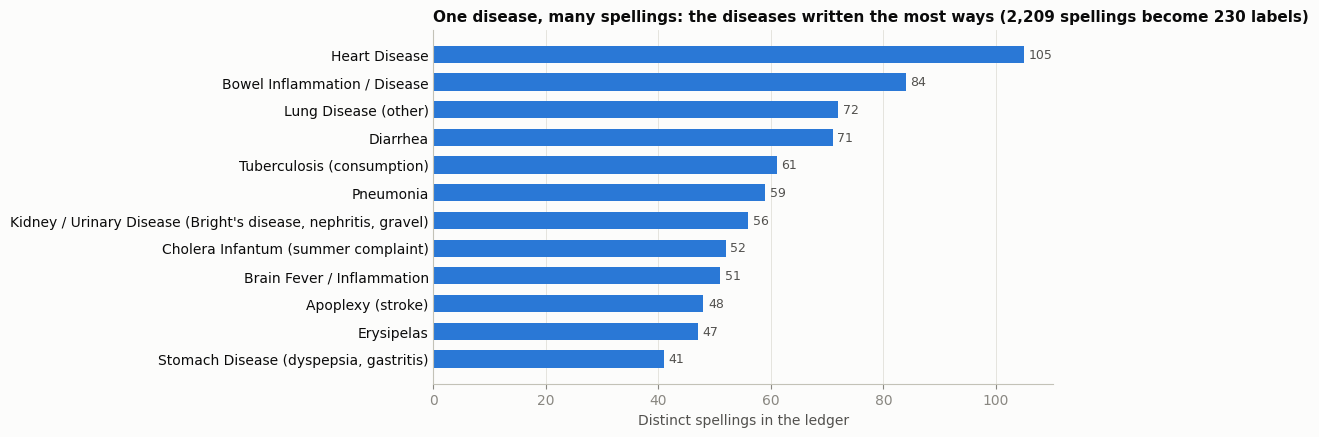

In [10]:
NOT_A_DISEASE = {rules.UNKNOWN, 'Accident', 'Gunshot', 'Homicide / Violence', 'Suicide', 'Drowning', 'Burns / Scalds', 'Poisoning / Overdose',
                 'Sudden Death', 'Suffocation (smothered, overlaid)', 'Exposure (heat or cold)', 'Wound (unspecified)', 'Killed in War'}
spellings = (uniq[(uniq['method'] == 'rule') & ~uniq['Cause of Death Updated'].isin(NOT_A_DISEASE)]
             .groupby('Cause of Death Updated')['as written'].nunique())
spellings = spellings.reset_index().sort_values(['as written', 'Cause of Death Updated'], ascending=[False, True]).set_index('Cause of Death Updated')['as written'].head(12)
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(spellings.index[::-1], spellings.values[::-1], color=BLUE, height=0.62)
for y, v in enumerate(spellings.values[::-1]):
    ax.text(v + 0.8, y, f'{v}', va='center', color=INK2, fontsize=9)
ax.set_title(f"One disease, many spellings: the diseases written the most ways ({cause_raw.nunique():,} spellings become {df['Cause of Death Updated'].nunique()} labels)", fontsize=11)
ax.set_xlabel('Distinct spellings in the ledger')
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
save(fig, 'q1_spellings.png')
fact('most_spelled', spellings.index[0])
fact('most_spelled_n', int(spellings.iloc[0]))
spellings.to_frame('distinct spellings')

## Question 2. Top 10 known causes of death

> **Prompt:** Find the top 10 known causes of death from the updated column.

"Known" means any label except `Unknown`, which covers blanks, "Unknown", "Not known" and notes that aren't causes.

In [11]:
upd = df['Cause of Death Updated']
known = upd[upd != rules.UNKNOWN]
top10 = (known.value_counts().rename_axis('cause').reset_index(name='burials')
         .sort_values(['burials', 'cause'], ascending=[False, True], kind='stable').head(10).reset_index(drop=True))
top10.index = range(1, 11)
top10['share of known causes'] = (top10['burials'] / len(known)).map(lambda x: pct(x))
top10['share of all burials'] = (top10['burials'] / len(df)).map(lambda x: pct(x))
# labels that name no specific disease (one definition, used here, in Question 3 and in the Question 9 cause families)
VAGUE = {'Complications (unspecified)', 'Fever (unspecified)', 'Inflammation (unspecified)', 'Congestion (unspecified)', 'Cold', 'Unknown'}
top10['vague label?'] = top10['cause'].isin(VAGUE).map({True: 'yes', False: ''})
top10.to_csv(RESULTS / 'top10_causes.csv', index_label='rank')

fact('n_unknown_cause', int((upd == rules.UNKNOWN).sum()))
fact('n_known_cause', len(known))
fact('pct_known', pct(len(known) / len(df)))
fact('top1', top10.loc[1, 'cause'])
fact('top1_n', int(top10.loc[1, 'burials']))
fact('top1_pct', top10.loc[1, 'share of known causes'])
fact('top2', top10.loc[2, 'cause'])
fact('top2_n', int(top10.loc[2, 'burials']))
fact('top3', top10.loc[3, 'cause'])
fact('top3_n', int(top10.loc[3, 'burials']))
fact('top10_list', '; '.join(f"{i}. {c} ({n:,})" for i, (c, n) in enumerate(zip(top10['cause'], top10['burials']), 1)))
fact('top10_share', pct(top10['burials'].sum() / len(known)))
specific = ranked(known[~known.isin(VAGUE)]).head(10)
fact('top10_specific', '; '.join(specific.index))
vague_in_top10 = top10.loc[top10['cause'].isin(VAGUE), 'cause'].tolist()
assert len(vague_in_top10) == 1, vague_in_top10
fact('top10_vague_in', vague_in_top10[0])
top10

,cause,burials,share of known causes,share of all burials,vague label?
1,Tuberculosis (consumption),1843,10.6%,9.4%,
2,Stillborn,1303,7.5%,6.6%,
3,Cholera,1253,7.2%,6.4%,
4,Pneumonia,798,4.6%,4.1%,
5,Complications (unspecified),755,4.3%,3.8%,yes
6,Brain Fever / Inflammation,661,3.8%,3.4%,
7,Old Age,623,3.6%,3.2%,
8,Teething,599,3.4%,3.0%,
9,Dysentery (flux),565,3.2%,2.9%,
10,Measles,498,2.9%,2.5%,


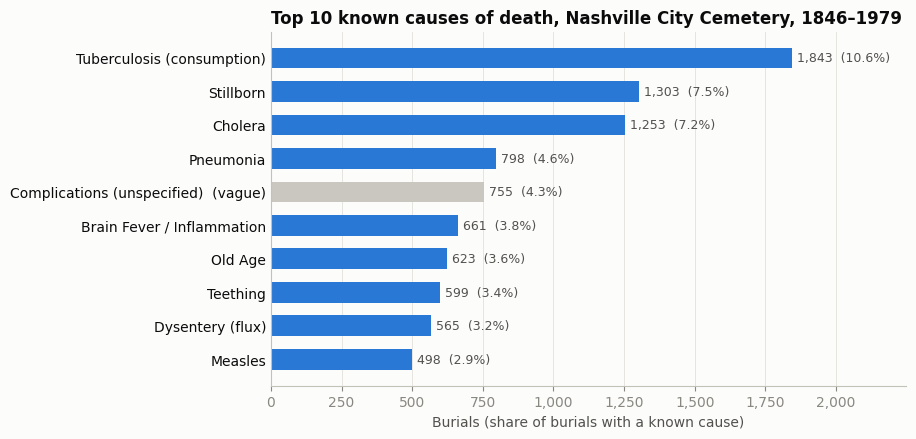

In [12]:
fig, ax = plt.subplots(figsize=(8.2, 4.6))
labels = [c + ('  (vague)' if c in VAGUE else '') for c in top10['cause']]
colors = [LIGHT_GRAY if c in VAGUE else BLUE for c in top10['cause']]
ax.barh(labels[::-1], top10['burials'].values[::-1], color=colors[::-1], height=0.62)
for y, (n, s) in enumerate(zip(top10['burials'].values[::-1], top10['share of known causes'].values[::-1])):
    ax.text(n + 18, y, f'{n:,}  ({s})', va='center', fontsize=9, color=INK2)
ax.set_title('Top 10 known causes of death, Nashville City Cemetery, 1846–1979')
ax.set_xlabel('Burials (share of burials with a known cause)')
ax.xaxis.set_major_formatter(COMMAS)
ax.set_xlim(0, top10['burials'].max() * 1.22)
ax.grid(axis='y', visible=False)
ax.tick_params(axis='y', length=0, labelcolor=INK)
save(fig, 'q2_top10_causes.png')

**Answer to Question 2.** Of 19,670 burials, 17,402 have a known cause. The top 10 known causes are: 1. Tuberculosis (consumption) (1,843); 2. Stillborn (1,303); 3. Cholera (1,253); 4. Pneumonia (798); 5. Complications (unspecified) (755); 6. Brain Fever / Inflammation (661); 7. Old Age (623); 8. Teething (599); 9. Dysentery (flux) (565); 10. Measles (498). Together they cover 51.1% of burials with a known cause.

**[REVIEW] Why other students' lists may differ.**
- **Grouping choices:** for example, whether "summer complaint" joins cholera infantum, or whether "flux" is counted with diarrhea.
- **Whether *Stillborn* and *Old Age* count as causes.** They're recorded in the cause column, so they're kept here.
- **Vague labels:** one entry in the top 10, *Complications (unspecified)*, names no specific disease. Set aside all five vague labels (Complications, Fever, Inflammation and Congestion, each "unspecified", and Cold) and the ten most frequent *specific* causes are: Tuberculosis (consumption); Stillborn; Cholera; Pneumonia; Brain Fever / Inflammation; Old Age; Teething; Dysentery (flux); Measles; Dropsy.
- **De-duplication:** it removes 75 repeated rows.

## Question 3. Years with a spike in burials, and does Claude's explanation hold up?

> **Prompt:** Find whether there were any years that had a spike in the number of burials. Explain the results. Does the explanation make sense? Do the numbers used as supporting evidence make sense?

**What counts as a spike?** The cemetery's yearly volume falls by 94% between the 1860's and the 1890's, so a single fixed threshold would flag nearly every early year. (The likely reason is that newer cemeteries took over. That is general knowledge, not something the ledger shows.) The rule below compares each year with the **median of the five years before it**. It flags a year that reaches **1.5×** that baseline *and* has at least **50 more burials** than it. The second condition stops tiny counts after 1900 from qualifying; for example, a year going from 16 to 28 burials. The rule needs at least three earlier years.

In [13]:
yearly = df.groupby('_year').size()
yearly.index = yearly.index.astype(int)
yearly = yearly.reindex(range(int(yearly.index.min()), int(yearly.index.max()) + 1), fill_value=0)
baseline = pd.Series([yearly.loc[max(yearly.index.min(), y - 5):y - 1].median() if y - yearly.index.min() >= 3 else np.nan
                      for y in yearly.index], index=yearly.index)
spikes = pd.DataFrame({'burials': yearly, 'baseline (median of 5 prior years)': baseline})
spikes['ratio'] = (spikes['burials'] / spikes['baseline (median of 5 prior years)']).round(2)
spikes['extra burials'] = (spikes['burials'] - spikes['baseline (median of 5 prior years)']).round(0)
# the rule compares unrounded values (the same way the DAX measure and the web prototype do)
flagged = spikes[(spikes['burials'] >= 1.5 * spikes['baseline (median of 5 prior years)'])
                 & (spikes['burials'] - spikes['baseline (median of 5 prior years)'] >= 50)].copy()
flagged['top known cause'], flagged['cholera burials'], flagged['Black burials'] = '', 0, 0

upd_year = df.dropna(subset=['_year'])
cholera_by_year = upd_year[upd_year['Cause of Death Updated'] == 'Cholera'].groupby('_year').size()
race = df['Race'].str.upper().str.strip(' .')
for y in flagged.index:
    s = upd_year[upd_year['_year'] == y]['Cause of Death Updated']
    top = ranked(s[s != rules.UNKNOWN])
    flagged.loc[y, 'top known cause'] = f"{top.index[0]} ({top.iloc[0]:,}, {pct(top.iloc[0] / len(s), 0)})"
    flagged.loc[y, 'cholera burials'] = int(cholera_by_year.get(y, 0))
    flagged.loc[y, 'Black burials'] = int(((df['_year'] == y) & (race == 'B')).sum())
flagged.to_csv(RESULTS / 'spike_years.csv', index_label='year')
spike_years = [int(y) for y in flagged.index]
assert spike_years == [1849, 1850, 1863, 1864, 1865, 1866, 1873], spike_years
fact('spike_years', '1849, 1850, 1863, 1864, 1865, 1866 and 1873')
fact('n_spike_years', len(spike_years))
flagged

,burials,baseline (median of 5 prior years),ratio,extra burials,top known cause,cholera burials,Black burials
_year,,,,,,,
1849,745,447.0,1.67,298.0,"Cholera (305, 41%)",305,224
1850,809,461.5,1.75,348.0,"Cholera (300, 37%)",300,237
1863,836,482.0,1.73,354.0,"Tuberculosis (consumption) (86, 10%)",0,356
1864,1372,575.0,2.39,797.0,"Measles (112, 8%)",0,725
1865,1366,627.0,2.18,739.0,"Tuberculosis (consumption) (100, 7%)",0,770
1866,1354,836.0,1.62,518.0,"Cholera (388, 29%)",388,804
1873,559,285.0,1.96,274.0,"Cholera (137, 25%)",137,184


In [14]:
def chol(y):
    return int(cholera_by_year.get(y, 0))

def share(y, n):
    return n / int(yearly.loc[y])

for y in [1849, 1850, 1854, 1866, 1873]:
    fact(f'chol_{y}', chol(y))
    fact(f'chol_{y}_pct', share(y, chol(y)), pct(share(y, chol(y)), 0))
    fact(f'n_{y}', int(yearly.loc[y]))
for y in [1849, 1850, 1866, 1873]:
    extra = float(yearly.loc[y] - baseline.loc[y])
    fact(f'excess_{y}', int(round(extra)))
    fact(f'chol_excess_{y}', chol(y) / extra, pct(chol(y) / extra, 0))
for y in [1860, 1861, 1863, 1864, 1865, 1866]:
    fact(f'b{y}', int(((df['_year'] == y) & (race == 'B')).sum()))
    fact(f'w{y}', int(((df['_year'] == y) & (race == 'W')).sum()))
for y in [1863, 1864, 1865]:
    fact(f'n_{y}', int(yearly.loc[y]))
war = ranked(upd_year[upd_year['_year'].between(1863, 1865)]['Cause of Death Updated'])
fact('war_measles_1864', int(((upd_year['_year'] == 1864) & (upd_year['Cause of Death Updated'] == 'Measles')).sum()))
war_named = war[~war.index.isin(VAGUE | {'Stillborn', 'Premature Birth', 'Teething'})]
war_lead = war_named[war_named >= war_named.iloc[4]]          # the top five, plus any tie with the fifth
fact('war_top', ', '.join(f"{c.split(' (')[0].lower()} {n:,}" for c, n in war_lead.items()))
gun = df['Cause of Death Updated'] == 'Gunshot'
fact('gun_pre', int((gun & df['_year'].between(1856, 1860)).sum()))
fact('gun_war', int((gun & df['_year'].between(1861, 1865)).sum()))
fact('gun_war_men', int((gun & df['_year'].between(1861, 1865) & (df['Sex'] == 'M')).sum()))
fact('gun_war_age', float(df.loc[gun & df['_year'].between(1861, 1865), '_age'].median()), f"{df.loc[gun & df['_year'].between(1861, 1865), '_age'].median():g}")
fact('gun_war_share', pct(FACTS['gun_war'] / int(yearly.loc[1861:1865].sum())))
for y in [1868, 1869, 1870]:
    fact(f'b{y}', int(((df['_year'] == y) & (race == 'B')).sum()))
free = df['Remarks'].str.lower().str.contains(r'f\. ?m\. ?c|f\. ?w\. ?c|free of color|\bfree\b', regex=True)
fact('free_1865', int((free & (df['_year'] == 1865)).sum()))
fact('free_1866', int((free & (df['_year'] == 1866)).sum()))
assert (free & (df['_year'] == 1846)).sum() > 0 and (free & (df['_year'] > 1867)).sum() == 0
fact('r1854', float(yearly.loc[1854] / baseline.loc[1854]), f"{yearly.loc[1854] / baseline.loc[1854]:.2f}×")
assert yearly.loc[1854] < 1.5 * yearly.loc[1851:1853].median()     # still no spike without 1849-50 in the baseline
fact('n_1869', int(yearly.loc[1869]))
fact('n_1868', int(yearly.loc[1868]))
fact('n_1870', int(yearly.loc[1870]))
fact('n_d_1869', int((race == 'D').sum()))
assert set(df.loc[race == 'D', '_year']) == {1869}
per_year = lambda a, b: yearly.loc[a:b].mean()
fact('decline_60s_90s', pct(1 - per_year(1890, 1899) / per_year(1860, 1869), 0))
fact('peak_year_n', int(yearly.max()))
fact('peak_year', int(yearly.idxmax()), str(int(yearly.idxmax())))
fact('after_1900_max', int(yearly.loc[1901:].max()))
fact('n_1846_1870', int(yearly.loc[1846:1870].sum()))
fact('share_before_1871', pct(yearly.loc[1846:1870].sum() / yearly.sum()))

'76.5%'

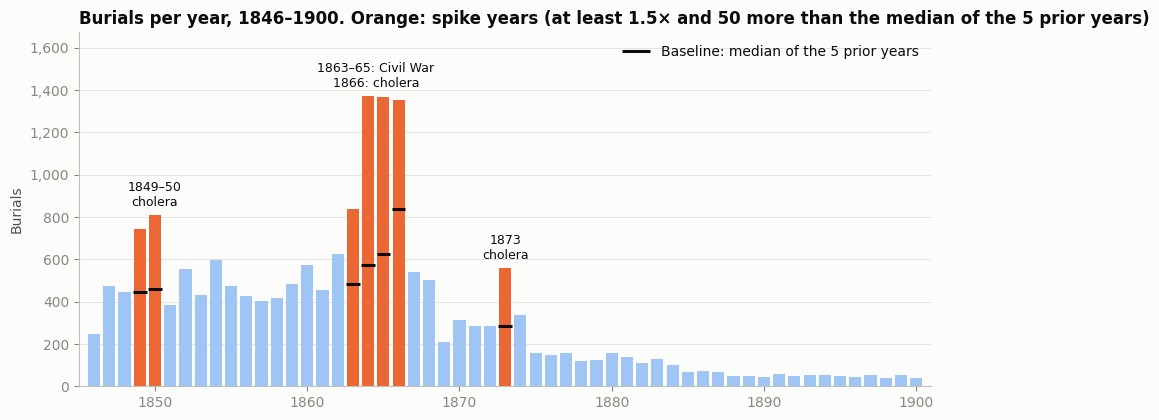

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.6))
yrs = yearly.loc[1846:1900]
cols = [ORANGE if y in spike_years else '#9ec5f4' for y in yrs.index]
ax.bar(yrs.index, yrs.values, color=cols, width=0.8)
for i, y in enumerate(spike_years):
    ax.hlines(baseline.loc[y], y - 0.45, y + 0.45, color=INK, lw=2.2, label='Baseline: median of the 5 prior years' if i == 0 else None)
notes = {1850: '1849–50\ncholera', 1864.5: '1863–65: Civil War\n1866: cholera', 1873: '1873\ncholera'}
for x, t in notes.items():
    top_y = yrs.loc[int(x) - 1:int(x) + 1].max()
    ax.text(x, top_y + 30, t, ha='center', va='bottom', fontsize=9, color=INK)
ax.set_ylim(0, yrs.max() * 1.22)
ax.set_xlim(1845, 1901)
ax.set_title('Burials per year, 1846–1900. Orange: spike years (at least 1.5× and 50 more than the median of the 5 prior years)')
ax.set_ylabel('Burials')
ax.yaxis.set_major_formatter(COMMAS)
ax.legend(loc='upper right')
ax.grid(axis='x', visible=False)
save(fig, 'q3_burials_by_year.png')

**[CLAUDE] Explanation of the spikes.** 7 years pass the 1.5× rule: 1849, 1850, 1863, 1864, 1865, 1866 and 1873.

1. **1849–1850: cholera.**
   - 1849 had 745 burials, and the updated cause column records cholera for 305 of them (41%).
   - 1850 had 809, with 300 cholera (37%).
   - A smaller cholera year, 1854, had 89 cholera burials out of 596. That is only 1.08× its baseline, so it doesn't pass the rule. (It would still fall short of 1.5× if 1849–50 were left out of the baseline.)
2. **1863–1865: the Civil War years, without cholera.**
   - Burials ran 836, 1,372 and 1,366 for the three years, and no cholera is recorded in 1863–65.
   - Leaving aside stillbirths, teething and vague labels, the leading causes for those years are tuberculosis 294, pneumonia 184, measles 175, whooping cough 145, brain fever / inflammation 134, dysentery 134. These are mostly respiratory and childhood infections, the kind that spread in crowded, poorly sheltered places; measles alone took 112 in 1864.
   - The increase falls mostly on **Black** Nashvillians. Black burials went from 140 in 1861 to 725 in 1864 and 770 in 1865. White burials went from 315 to 646 and 589.
   - Remarks such as "f. m. c." (free man of color) and "free" peak at 660 rows in 1865 and 770 in 1866.
3. **1866: cholera on top of the wartime level.** 388 of 1,354 burials (29%) are cholera. Black burials reached 804.
4. **1873: cholera again.** 137 of 559 burials (25%).

**Context from Claude's general knowledge.** This was not checked against sources in this notebook, because this session had no web access; Juan should verify it before citing.
- The United States had cholera epidemics in 1849–50, 1854, 1866 and 1873, and Nashville was hit in those waves.
- Union troops occupied Nashville in February 1862 and held it for the rest of the war, which made it a supply and hospital center.
- Thousands of people escaping slavery came to the occupied city, and many lived in crowded camps.
- Slavery ended in Tennessee in early 1865. That fits the jump in "free" remarks. They appear from 1846 on, when "f. m. c." marked free people of color, but jump to 660 rows in 1865 and 770 in 1866, then stop after 1867.

In [16]:
# [CHECK] recount the cholera numbers straight from the raw text, and test the other claims (asserted)
text = df['Cause of Death/Burial'].str.lower()
asiatic = (text.str.contains(r'chol|colera|chalera', regex=True)
           & ~text.str.contains(r'morb|mobis|mobus|fobus|inf|inph|cholic|cholick|colic', regex=True))
for y in [1849, 1850, 1854, 1866, 1873]:
    by_raw_text = int((asiatic & (df['_year'] == y)).sum())
    assert by_raw_text == FACTS[f'chol_{y}'], (y, by_raw_text, FACTS[f'chol_{y}'])
for y in [1863, 1864, 1865]:
    assert FACTS.get(f'chol_{y}', chol(y)) == 0 and chol(y) == 0
assert int(yearly.sum()) == len(df) - int(df['_year'].isna().sum())
assert FACTS['b1866'] > 4 * FACTS['b1861'] and FACTS['w1866'] < 2 * FACTS['w1861']
assert [TEXT[f'chol_excess_{y}'] for y in (1849, 1850, 1866, 1873)] == ['102%', '86%', '75%', '50%']
assert FACTS['b1864'] > FACTS['w1864'] > FACTS['w1861'] and FACTS['gun_war'] > 4 * FACTS['gun_pre']
print('the cholera counts match an independent count of the raw text, and the other checks pass')

the cholera counts match an independent count of the raw text, and the other checks pass


**[CHECK] Do the supporting numbers make sense? Yes (asserted).**
- Each cholera count was recomputed straight from the raw text, independently of the cleaning rules: any spelling containing "chol" or "colera", excluding the morbus, infantum and colic spellings. The two methods agree for every year quoted. The race counts also come straight from the `Race` column.
- Cholera is large enough to account for the cholera spikes. In 1849, cholera burials alone (305) exceed the extra burials above the baseline (298). They equal 86% of 1850's extra burials, 75% of 1866's and 50% of 1873's.

**[REVIEW] Does the explanation make sense?**
- **Cholera years: yes.** The ledger names the cause directly in 1849–50, 1866 and 1873.
- **War years: yes, with a correction to the obvious story.** The obvious story would be young soldiers. Wounds do show up: gunshot burials rose from 12 in 1856–60 to 61 in 1861–65, and 59 of those 61 were men (median age 27). But that is only 1.3% of the war years' burials. The cause column is dominated by camp and crowding diseases, the increase is concentrated in Black burials, and Question 4 finds no rise in the share of young men.
- **What doesn't make sense, or needs a human:**
  - **The long decline after 1870 is not evidence of falling mortality.** Most likely burials moved to newer cemeteries (general knowledge, not shown in the ledger). After 1900 no year has more than 41 burials, and 76.5% of all burials in the ledger happened before 1871.
  - **1869 looks like a gap in the records, not a healthy year.** It has 209 burials, against 504 in 1868 and 312 in 1870, and infant entries fall to 52: 25% of the year's burials, against 51% in 1868 (Question 8). It is also the only year that uses the unexplained race code `D` (69 rows), while only 31 burials are coded `B` (against 305 in 1868 and 87 in 1870). So `D` may stand for Black in that volume. This notebook leaves `D` as "other", and that is a judgment call for Juan.
  - **The ledger covers only this cemetery.** These are counts of burials here, not of deaths across Nashville.

## Question 4. Did the Civil War change the age of those buried?

> **Prompt:** There seems to be a spike during the Civil War. Ask Claude if the Civil War had any impact on the age of those being buried. Do the values and explanation make sense?

**What Claude expected before looking.** War years bring young men, so expect a higher share of young adults (18–30), a higher male share among them, and a lower median age. The test compares three five-year windows:
- **Before:** 1856–60
- **War:** 1861–65
- **After:** 1866–70

In [17]:
PERIODS = {'before (1856-60)': (1856, 1860), 'war (1861-65)': (1861, 1865), 'after (1866-70)': (1866, 1870)}
rng = np.random.default_rng(42)

def median_ci(a, n_boot=2000):
    a = np.asarray(a, dtype=float)
    meds = np.median(rng.choice(a, size=(n_boot, len(a)), replace=True), axis=1)
    return float(np.median(a)), float(np.percentile(meds, 2.5)), float(np.percentile(meds, 97.5))

grp_all = age_group(df['Age'])
rows = []
for who, mask in {'all': pd.Series(True, index=df.index), 'White': race == 'W', 'Black': race == 'B'}.items():
    for label, (lo, hi) in PERIODS.items():
        m = mask & df['_year'].between(lo, hi)
        s = df[m]
        g = grp_all[m]
        ages = s['_age'].dropna()
        med, lo_ci, hi_ci = median_ci(ages)
        ya = s[g == 'young adults']
        rows.append({'who': who, 'period': label, 'burials': len(s), 'age recorded': pct(ages.size / len(s), 0),
                     'median age': med, '95% CI': f'{lo_ci:g}–{hi_ci:g}',
                     'young adults (18-30)': pct((g == 'young adults').mean()),
                     'men among young adults': pct((ya['Sex'] == 'M').mean(), 0),
                     'child (<=5)': pct((g == 'child').mean()), 'minors (6-17)': pct((g == 'minors').mean()),
                     'older adults (51+)': pct((g == 'older adults').mean()), 'unknown age': pct((g == 'unknown').mean())})
civil = pd.DataFrame(rows)
civil.to_csv(RESULTS / 'civil_war_age.csv', index=False)

def cell(who, period, col):
    return civil[(civil['who'] == who) & (civil['period'].str.startswith(period))][col].iloc[0]

for who, k in [('all', 'all'), ('White', 'w'), ('Black', 'b')]:
    for p, kp in [('before', 'pre'), ('war', 'war'), ('after', 'post')]:
        fact(f'q4_{k}_{kp}', float(cell(who, p, 'median age')), f"{cell(who, p, 'median age'):g}")
        fact(f'q4_{k}_{kp}_ci', cell(who, p, '95% CI'))
        fact(f'q4_{k}_{kp}_ya', cell(who, p, 'young adults (18-30)'))
        fact(f'q4_{k}_{kp}_men', cell(who, p, 'men among young adults'))
        fact(f'q4_{k}_{kp}_n', int(cell(who, p, 'burials')))
        fact(f'q4_{k}_{kp}_unk', cell(who, p, 'unknown age'))
        fact(f'q4_{k}_{kp}_minors', cell(who, p, 'minors (6-17)'))
        fact(f'q4_{k}_{kp}_old', cell(who, p, 'older adults (51+)'))
ya_1866 = (df['_year'] == 1866) & (grp_all == 'young adults')
fact('q4_ya_cholera_1866', pct((df.loc[ya_1866, 'Cause of Death Updated'] == 'Cholera').mean(), 0))
post = df['_year'].between(1866, 1870) & ~((df['_year'] == 1866) & (df['Cause of Death Updated'] == 'Cholera'))
fact('q4_post_ya_no_chol', pct((grp_all[post] == 'young adults').mean()))
war_m = df['_year'].between(1861, 1865)
post_all = df['_year'].between(1866, 1870)
fact('q4_all_war_rec', pct((grp_all[war_m] != 'unknown').mean()))
fact('q4_all_post_rec', pct((grp_all[post_all] != 'unknown').mean()))
fact('q4_all_war_mid', pct((grp_all[war_m] == 'middle aged').mean()))
fact('q4_all_post_mid', pct((grp_all[post_all] == 'middle aged').mean()))
fact('q4_war_ya_rec', pct((grp_all[war_m & (grp_all != 'unknown')] == 'young adults').mean()))
fact('q4_post_ya_rec_no_chol', pct((grp_all[post & (grp_all != 'unknown')] == 'young adults').mean()))
inf_name = df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|babe|baby', regex=True)
fact('q4_war_inf_n', int((inf_name & war_m).sum()))
fact('q4_war_inf_aged', int((inf_name & war_m & (grp_all != 'unknown')).sum()))
fact('q4_post_inf_n', int((inf_name & post_all).sum()))
fact('q4_post_inf_aged', int((inf_name & post_all & (grp_all != 'unknown')).sum()))
assert float(TEXT['q4_all_war_ya'][:-1]) < float(TEXT['q4_post_ya_no_chol'][:-1]) < float(TEXT['q4_all_post_ya'][:-1])
civil

,who,period,burials,age recorded,median age,95% CI,young adults (18-30),men among young adults,child (<=5),minors (6-17),older adults (51+),unknown age
0,all,before (1856-60),2302,51%,33.0,31–35,14.2%,46%,1.7%,8.0%,12.7%,49.0%
1,all,war (1861-65),4656,49%,30.0,28–30,13.4%,44%,1.9%,10.7%,11.4%,50.8%
2,all,after (1866-70),2921,59%,30.0,28–30,18.9%,49%,2.4%,10.0%,11.0%,41.5%
3,White,before (1856-60),1560,49%,32.0,30–34,14.6%,50%,1.9%,7.2%,10.8%,50.8%
4,White,war (1861-65),2458,50%,32.0,30–34,14.0%,45%,1.9%,8.5%,12.5%,49.9%
5,White,after (1866-70),1335,58%,31.0,30–33,17.8%,53%,2.7%,7.7%,11.5%,42.4%
6,Black,before (1856-60),741,55%,35.0,31–40,13.5%,39%,1.5%,9.6%,16.7%,45.2%
7,Black,war (1861-65),2188,48%,27.0,25–28,12.7%,42%,1.8%,13.2%,10.2%,51.6%
8,Black,after (1866-70),1513,59%,28.0,26–30,19.4%,47%,1.5%,12.2%,10.8%,41.2%


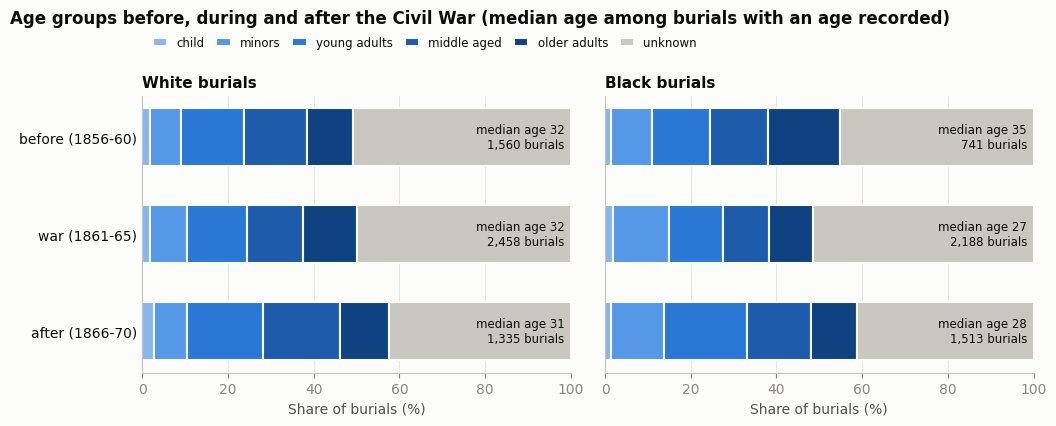

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), sharex=True)
for ax, who in zip(axes, ['White', 'Black']):
    left = np.zeros(3)
    for g in AGE_ORDER:
        vals = []
        for label, (lo, hi) in PERIODS.items():
            m = (race == ('W' if who == 'White' else 'B')) & df['_year'].between(lo, hi)
            vals.append((grp_all[m] == g).mean() * 100)
        ax.barh(list(PERIODS)[::-1], vals[::-1], left=left[::-1], color=AGE_COLORS[g], height=0.6,
                edgecolor=SURFACE, linewidth=1.5, label=g)
        left = left + np.array(vals)
    for y, label in enumerate(list(PERIODS)[::-1]):
        n = cell(who, label.split(' ')[0], 'burials')
        med = cell(who, label.split(' ')[0], 'median age')
        ax.text(98.5, y, f'median age {med:g}\n{n:,} burials', va='center', ha='right', fontsize=8.5, color=INK)
    ax.set_title(f'{who} burials', fontsize=11)
    ax.set_xlim(0, 100)
    ax.set_xlabel('Share of burials (%)')
    ax.grid(axis='y', visible=False)
    ax.tick_params(axis='y', length=0, labelcolor=INK)
axes[1].tick_params(axis='y', labelleft=False)
axes[0].legend(ncol=6, loc='lower left', bbox_to_anchor=(0, 1.13), fontsize=8.5, handlelength=1.2, columnspacing=1)
fig.suptitle('Age groups before, during and after the Civil War (median age among burials with an age recorded)', x=0.01, ha='left', y=1.12, fontsize=12, fontweight='bold')
fig.subplots_adjust(wspace=0.08)
save(fig, 'q4_civil_war_age.png')

**[CHECK] Does the data match the expectation? Mostly no.** The medians are computed from burials with an age recorded; the bootstrap 95% CIs come from 2,000 resamples (seed 42).
- **All burials, median recorded age:**
  - Before: 33 (95% CI 31–35)
  - War: 30 (CI 28–30)
  - After: 30 (CI 28–30)
- **Young adults (18–30)** did not rise during the war: 14.2% → 13.4%. Men were 46% of young adults before and 44% during. A soldier-driven spike would raise both.
- **The change is among Black burials:**
  - Median recorded age fell from 35 (CI 31–40) to 27 (CI 25–28), while Black burials nearly tripled (741 → 2,188).
  - The shift comes from more minors (6–17) and fewer older adults, not from young adults: minors rose from 9.6% to 13.2% of Black burials, and older adults fell from 16.7% to 10.2%. Young adults stayed flat at 13.5% → 12.7%.
  - The median age of White burials did not move (32 → 32), although their number rose from 1,560 to 2,458.
- **After the war**, young adults rose to 18.9% of all burials. Two things contribute, and they overlap:
  - **The 1866 cholera.** It caused 43% of young-adult burials that year. Leave out the 1866 cholera burials and the share is 16.6%.
  - **Fewer infant entries in the mix.** 58.5% of burials have an age written after the war, against 49.2% during it. That is not because clerks started writing infants' ages: they gave one to 1 of 2,287 infant-named entries in 1861–65, and to 16 of 1,147 in 1866–70. There were fewer infant entries, partly because of the 1869 gap (Question 8). The 1866 cholera burials, which mostly have an age, also add to this share, which is where the two points overlap. Most of the gain goes to young and middle-aged adults (middle aged: 11.9% → 16.2%).
  - **A smaller rise remains.** Counting only burials with an age and leaving out the 1866 cholera, young adults are 30.5% after the war, against 27.1% during it.

**[REVIEW] Does the explanation make sense?**
- **What holds up:**
  - The war did change who was buried here. The overall median fell by three years (33 → 30, with non-overlapping CIs), because many more Black Nashvillians were buried, and more of them were children and teenagers.
  - The causes in Question 3 (consumption, pneumonia, measles, whooping cough) fit refugees in crowded camps better than battle deaths.
- **What a human must keep in mind:**
  - **Age is missing for half of these burials** (50.8% during the war), and most of the missing are infants. The medians describe the people whose age was written down. For the same reason, "child" looks rare.
  - **Soldiers may be under-recorded here.** From general knowledge (not verified here), many soldiers were buried in separate grounds and later moved. A few remarks mention a "Soldier Yard" or "Southern Soldier Ground", but this ledger can't count them.
  - **The CIs overlap for White burials** (no detectable change), **but not for Black burials**.

## Question 5. Add a `decade` column next to the year

> **Prompt:** Make a new column named 'decade' next to the Year column, in the format 1840's.

In [19]:
pos = df.columns.get_loc('Burial Year') + 1
df.insert(pos, 'decade', decade_label(df['Burial Year']))
assert list(df.columns[pos - 1:pos + 1]) == ['Burial Year', 'decade']
assert (df.loc[df['Burial Year'] == '1846', 'decade'] == "1840's").all()
assert (df.loc[df['Burial Year'] == '1979', 'decade'] == "1970's").all()
assert (df.loc[df['Burial Year'] == '', 'decade'] == 'unknown').all()
assert df['decade'].str.fullmatch(r"\d{3}0's|unknown").all()
fact('n_decade_unknown', int((df['decade'] == 'unknown').sum()))
dec = df['decade'].value_counts().sort_index()
fact('top_decade', dec.drop('unknown', errors='ignore').idxmax())
fact('top_decade_n', int(dec.drop('unknown', errors='ignore').max()))
fact('top_decade_pct', pct(dec.drop('unknown', errors='ignore').max() / len(df)))
df[['Burial Year', 'decade']].drop_duplicates().head(3)

,Burial Year,decade
0,1979,1970's
3,1978,1970's
5,1977,1970's


In [20]:
dec.to_frame('burials').T

decade,1840's,1850's,1860's,1870's,1880's,1890's,1900's,1910's,1920's,1930's,1940's,1950's,1960's,1970's,unknown
burials,1914,4974,7840,2482,941,489,330,244,176,143,79,27,15,14,2


**[CHECK] (asserted).**
- `decade` sits immediately to the right of `Burial Year`.
- 1846 → `1840's` and 1979 → `1970's`.
- Every value matches the `1840's` pattern. The 2 rows with no year get `unknown`, the same convention Question 6 uses for blank ages.

**Answer to Question 5.** The busiest decade is the 1860's, with 7,840 burials (39.9% of the whole ledger).

## Question 6. Add an `age group` column next to age

> **Prompt:** Make a new column named 'age group' next to age. Children 5 or less are listed as child, 6–17 as minors, 18–30 as young adults, 31–50 as middle aged, and older than 50 as older adults. If age is blank, fill in the age group as unknown.

The labels are used exactly as the assignment writes them. Ages in this ledger are whole years. If a fractional age ever appears, it's floored (age at last birthday), so 5½ counts as 5 → child and there is no gap between "5 or less" and "6".

In [21]:
pos = df.columns.get_loc('Age') + 1
df.insert(pos, 'age group', age_group(df['Age']))
assert list(df.columns[pos - 1:pos + 1]) == ['Age', 'age group']
probe = pd.Series(['0', '5', '6', '17', '18', '30', '31', '50', '51', '116', '', '5.5'])
assert list(age_group(probe)) == ['child', 'child', 'minors', 'minors', 'young adults', 'young adults',
                                  'middle aged', 'middle aged', 'older adults', 'older adults', 'unknown', 'child']
assert (df.loc[df['Age'].str.strip() == '', 'age group'] == 'unknown').all()
assert set(df['age group']) == set(AGE_ORDER)

ag = df['age group'].value_counts().reindex(AGE_ORDER)
unknown = df['age group'] == 'unknown'
infant_like = (df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|babe|baby', regex=True)
               | df['Cause of Death Updated'].isin(['Stillborn', 'Premature Birth', 'Teething', 'Cholera Infantum (summer complaint)', 'Thrush', 'Hives']))
fact('unknown_n', int(unknown.sum()))
fact('unknown_pct', pct(unknown.mean()))
fact('unk_infant_n', int((unknown & infant_like).sum()))
fact('unk_infant_pct', pct((unknown & infant_like).sum() / unknown.sum()))
fact('child_n', int(ag['child']))
fact('median_age_all', float(df['_age'].median()), f"{df['_age'].median():g}")
fact('older_n', int(ag['older adults']))
pd.DataFrame({'burials': ag, 'share': (ag / len(df)).map(pct)}).T

age group,child,minors,young adults,middle aged,older adults,unknown
burials,820,1628,2701,2717,3145,8659
share,4.2%,8.3%,13.7%,13.8%,16.0%,44.0%


**[CHECK] (asserted).**
- `age group` sits immediately to the right of `Age`.
- Every boundary is tested: 5 → child, 6 → minors, 17/18, 30/31, 50/51, and blank → unknown.

**[REVIEW] The literal rule hides most of the babies.**
- 8,659 burials (44.0%) have no age, so they're "unknown". But 89.5% of those (7,747) have an infant-like name ("Infant", "Inft.", "Still born") or an infant cause (stillborn, teething, cholera infantum…).
- Only 820 burials are recorded as "child", although infants make up the largest group in the ledger.
- The column follows the assignment exactly, as requested. Every chart and interpretation below reads "unknown" as "mostly infants". That's a human judgment the column alone doesn't carry.

## Question 7. Burials and the most common burial decade for each age group

> **Prompt:** Make a visualization that shows the count of burials and the most common burial decade for each age group. Was there anything interesting in these results? What is Claude's interpretation?

In [22]:
ct = pd.crosstab(df['age group'], df['decade']).reindex(index=AGE_ORDER)
ct = ct[[c for c in ct.columns if c != 'unknown']]
mode_dec = ct.idxmax(axis=1)
mode_n = ct.max(axis=1)
summary7 = pd.DataFrame({'burials': ag, 'most common decade': mode_dec, 'burials in that decade': mode_n,
                         "share of the group's burials": (mode_n / ag).map(pct)})
row_share = ct.div(ct.sum(axis=1), axis=0)
late = row_share[[c for c in row_share.columns if int(c[:4]) >= 1880]].sum(axis=1)
summary7['share buried 1880 or later'] = late.map(pct)
summary7.to_csv(RESULTS / 'age_group_decade.csv')
ct.to_csv(RESULTS / 'age_group_by_decade_counts.csv')
for g in AGE_ORDER:
    k = g.replace(' ', '_')
    fact(f'q7_{k}_mode', mode_dec[g])
    fact(f'q7_{k}_share', summary7.loc[g, "share of the group's burials"])
    fact(f'q7_{k}_late', pct(late[g]))
fact('q7_n_peak_1860s', int((mode_dec == "1860's").sum()))
infant_named = df['Name'].str.lower().str.contains(r'\binf\w*|\binft|still|babe|baby', regex=True)
age_written = (infant_named & (df['age group'] != 'unknown')).groupby(df['decade']).sum() / infant_named.groupby(df['decade']).sum()
for d in ["1840's", "1850's", "1860's"]:
    fact(f"q7_infant_age_written_{d[:4]}", pct(age_written[d]))
summary7

,burials,most common decade,burials in that decade,share of the group's burials,share buried 1880 or later
age group,,,,,
child,820,1850's,307,37.4%,16.8%
minors,1628,1860's,815,50.1%,5.0%
young adults,2701,1860's,1213,44.9%,6.5%
middle aged,2717,1860's,1059,39.0%,11.6%
older adults,3145,1860's,868,27.6%,33.7%
unknown,8659,1860's,3721,43.0%,8.0%


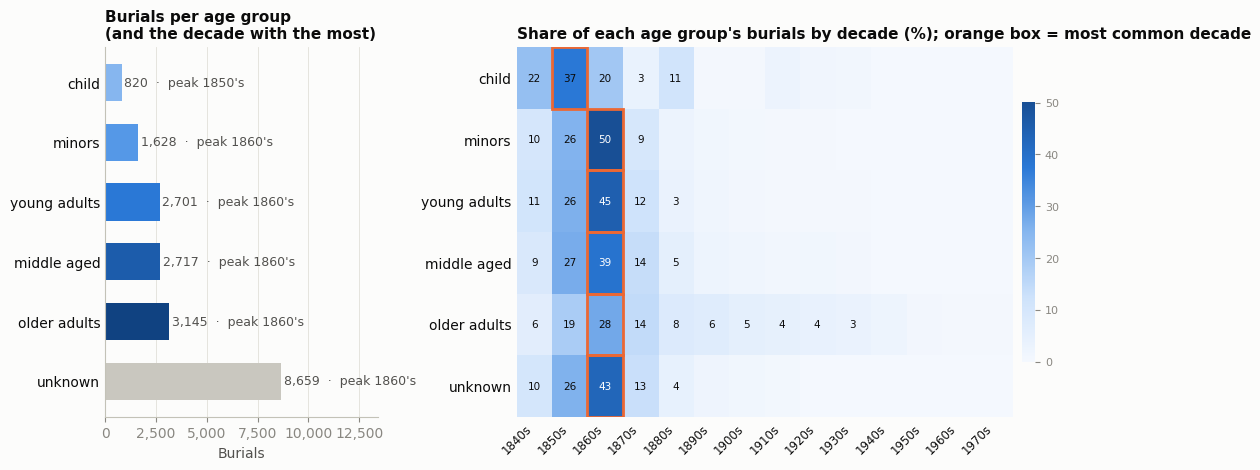

In [23]:
fig = plt.figure(figsize=(12, 4.8))
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1.9], wspace=0.35)
ax = fig.add_subplot(gs[0])
y = np.arange(len(AGE_ORDER))[::-1]
ax.barh(y, ag.values, color=[AGE_COLORS[g] for g in AGE_ORDER], height=0.62)
for yy, g in zip(y, AGE_ORDER):
    ax.text(ag[g] + 120, yy, f"{ag[g]:,}  ·  peak {mode_dec[g]}", va='center', fontsize=9, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels(AGE_ORDER)
ax.tick_params(axis='y', length=0, labelcolor=INK)
ax.set_xlim(0, ag.max() * 1.55)
ax.set_xlabel('Burials')
ax.xaxis.set_major_formatter(COMMAS)
ax.grid(axis='y', visible=False)
ax.set_title('Burials per age group\n(and the decade with the most)', fontsize=11)

ax2 = fig.add_subplot(gs[1])
cmap = LinearSegmentedColormap.from_list('blues', ['#f4f8fe', '#cde2fb', '#86b6ef', '#2a78d6', '#184f95'])
vmax = max(40, row_share.values.max() * 100)
im = ax2.imshow(row_share.values * 100, aspect='auto', cmap=cmap, vmin=0, vmax=vmax)

def text_on(rgba):
    # white or black text, whichever contrasts more with the cell color
    lin = [c / 12.92 if c <= 0.03928 else ((c + 0.055) / 1.055) ** 2.4 for c in rgba[:3]]
    lum = 0.2126 * lin[0] + 0.7152 * lin[1] + 0.0722 * lin[2]
    return 'white' if 1.05 / (lum + 0.05) > (lum + 0.05) / 0.0533 else INK

ax2.set_xticks(range(len(row_share.columns)))
ax2.set_xticklabels([c.replace("'s", 's') for c in row_share.columns], rotation=45, ha='right', fontsize=8.5)
ax2.set_yticks(range(len(AGE_ORDER)))
ax2.set_yticklabels(AGE_ORDER)
ax2.tick_params(length=0, labelcolor=INK)
ax2.grid(False)
for i, g in enumerate(AGE_ORDER):
    for j, c in enumerate(row_share.columns):
        v = row_share.loc[g, c] * 100
        if v >= 3:
            ax2.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=7.5, color=text_on(cmap(v / vmax)))
    j = list(row_share.columns).index(mode_dec[g])
    ax2.add_patch(Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor=ORANGE, lw=2))
for s in ax2.spines.values():
    s.set_visible(False)
ax2.set_title("Share of each age group's burials by decade (%); orange box = most common decade", fontsize=11)
cb = fig.colorbar(im, ax=ax2, fraction=0.025, pad=0.02)
cb.outline.set_visible(False)
cb.ax.tick_params(labelsize=8, colors=MUTED)
save(fig, 'q7_age_group_decades.png')

**[CLAUDE] Interpretation.**
- **5 of the six groups peak in the 1860's.** That is less interesting than it looks: the 1860's is the busiest decade in the whole ledger (Question 5), so most groups will peak there. The left chart answers the question as asked, but the heatmap is more informative. It shows what share of each group's burials fell in each decade.
- **The exception, "child", peaks in the 1850's (37.4% of the group).** This is about record keeping, not about children. In the 1840's, clerks wrote an age for 10.3% of the infant-named entries ("Infant", "Inft.", "Still born", "Baby"); in the 1850's for 5.9%; in the 1860's for only 0.4%. So young children in the 1860's mostly land in "unknown", not "child".
- **Older adults spread across later decades.** 33.7% of older-adult burials happened in 1880 or later, against 6.5% for young adults and 8.0% for the unknown (mostly infant) group. A plausible reason: as the cemetery filled and other cemeteries opened, the people still buried here were more often older family members going into existing family lots.
- **The unknown group follows the 1860's peak (43.0% of it falls in that decade).** That is when infants were most often written down without an age.

**[REVIEW] Does it make sense?** Yes, read alongside two facts:
1. The decades differ hugely in volume, so compare within-group shares, not raw peaks.
2. "Unknown" is mostly infants (Question 6).

The "older adults moving into family lots" reading is a plausible explanation, not something the ledger proves. The `Ave` and `Section/Lot` columns could be used to test it.

## Question 8. Burials by age group for each year of the 1860's

> **Prompt:** Count the number of burials by age group for each year of the 1860's. Was there anything interesting in these results? What is Claude's interpretation?

In [24]:
s60 = df[df['_year'].between(1860, 1869)]
pv = pd.crosstab(s60['_year'].astype(int), s60['age group']).reindex(columns=AGE_ORDER, fill_value=0)
pv['total'] = pv.sum(axis=1)
pv.index.name = 'year'
pv.to_csv(RESULTS / 'age_group_1860s.csv')
idx = (pv[AGE_ORDER].div(pv.loc[1860, AGE_ORDER]) * 100).round(0)
peak = pv[AGE_ORDER].idxmax()
for g in AGE_ORDER:
    k = g.replace(' ', '_')
    fact(f'q8_{k}_peak', int(peak[g]), str(int(peak[g])))
    fact(f'q8_{k}_1860', int(pv.loc[1860, g]))
    fact(f'q8_{k}_max', int(pv[g].max()))
    fact(f'q8_{k}_x', f"{pv[g].max() / pv.loc[1860, g]:.1f}×")
fact('q8_total_1860', int(pv.loc[1860, 'total']))
fact('q8_total_1864', int(pv.loc[1864, 'total']))
fact('q8_total_1869', int(pv.loc[1869, 'total']))
fact('q8_unknown_1868', int(pv.loc[1868, 'unknown']))
fact('q8_unknown_1869', int(pv.loc[1869, 'unknown']))
fact('q8_child_1868', int(pv.loc[1868, 'child']))
fact('q8_child_1869', int(pv.loc[1869, 'child']))
cause60 = df['Cause of Death Updated']
def cause_share(year, group, cause):
    m = (df['_year'] == year) & (df['age group'] == group)
    return (cause60[m] == cause).mean()
fact('q8_ya_cholera_1866', pct(cause_share(1866, 'young adults', 'Cholera'), 0))
fact('q8_ma_cholera_1866', pct(cause_share(1866, 'middle aged', 'Cholera'), 0))
fact('q8_unk_measles_1864', pct(cause_share(1864, 'unknown', 'Measles'), 0))
fact('q8_child_measles_1864', pct(cause_share(1864, 'child', 'Measles'), 0))
fact('q8_unk_measles_1864_n', int(((df['_year'] == 1864) & (df['age group'] == 'unknown') & (cause60 == 'Measles')).sum()))
for y in [1868, 1869, 1870]:                              # infant-like entries as defined in Question 6
    in_year = df['_year'] == y
    fact(f'inf_{y}', int((infant_like & in_year).sum()))
    fact(f'inf_{y}_pct', pct((infant_like & in_year).sum() / in_year.sum(), 0))
fact('q8_unk_rise_1864', int(pv.loc[1864, 'unknown'] - pv.loc[1860, 'unknown']))
for grp in ['unknown', 'child']:       # measles is the leading named cause in 1864 for these two groups
    named = ranked(cause60[(df['_year'] == 1864) & (df['age group'] == grp) & ~cause60.isin(VAGUE)])
    assert named.index[0] == 'Measles', (grp, named.head(3))
assert (pv.loc[[1864, 1865], AGE_ORDER] > pv.loc[1860, AGE_ORDER]).all().all()
pv

age group,child,minors,young adults,middle aged,older adults,unknown,total
year,,,,,,,
1860,12,48,87,84,62,282,575
1861,11,54,59,61,56,214,455
1862,16,56,93,82,89,291,627
1863,12,78,103,109,116,418,836
1864,31,165,169,138,131,738,1372
1865,17,144,198,166,139,702,1366
1866,18,154,304,235,148,495,1354
1867,6,52,88,83,52,261,542
1868,19,49,60,69,52,255,504


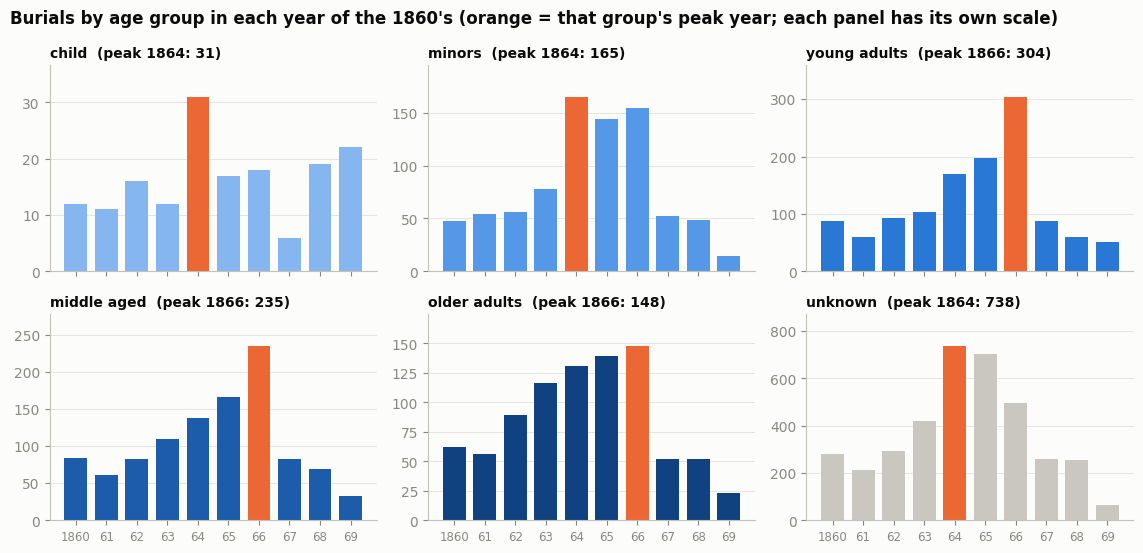

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(11.5, 5.6), sharex=True)
for ax, g in zip(axes.flat, AGE_ORDER):
    vals = pv[g]
    cols = [AGE_COLORS[g] if y != peak[g] else ORANGE for y in vals.index]
    ax.bar(vals.index, vals.values, color=cols, width=0.75)
    ax.set_title(f'{g}  (peak {peak[g]}: {vals.max():,})', fontsize=10)
    ax.set_ylim(0, vals.max() * 1.18)
    ax.grid(axis='x', visible=False)
    ax.set_xticks(range(1860, 1870))
    ax.set_xticklabels([str(y)[2:] if y != 1860 else '1860' for y in range(1860, 1870)], fontsize=8.5)
fig.suptitle("Burials by age group in each year of the 1860's (orange = that group's peak year; each panel has its own scale)",
             x=0.01, ha='left', fontsize=12, fontweight='bold')
fig.tight_layout()
save(fig, 'q8_age_groups_1860s.png')

**[CLAUDE] Interpretation.**
- **Every group is higher in 1864 and 1865 than in 1860, but the groups peak in different years:**

  | Group | Peak year | Burials, 1860 → peak year |
  |---|---|---|
  | child (recorded ≤ 5) | 1864 | 12 → 31 (2.6×) |
  | minors | 1864 | 48 → 165 (3.4×) |
  | young adults | 1866 | 87 → 304 (3.5×) |
  | middle aged | 1866 | 84 → 235 (2.8×) |
  | older adults | 1866 | 62 → 148 (2.4×) |
  | unknown (mostly infants) | 1864 | 282 → 738 (2.6×) |

- **The peaks split by age.**
  - The young groups (unknown, minors, recorded children) peak in **1864**. Measles was the leading named cause that year among unknown-age burials (11%) and recorded children (23%). It explains only part of the rise, though: 80 of the 456 extra unknown-age burials since 1860.
  - The adult groups peak in **1866**, the cholera year. Cholera caused 43% of 1866's young-adult burials and 43% of its middle-aged ones.
- **The war-time surge is broad, not a young-men surge.** Every group is higher in 1864–65 than in 1860, which is what disease spreading through a crowded city would do. This matches Questions 3 and 4: refugees and camp diseases, then cholera in 1866.
- **Small groups make "peak year" fragile.** The recorded-child group has so few burials per year that its peak can be a handful of entries.
- **1869 is odd.** Total burials fall to 209. Infant-like entries fall from 255 in 1868 (51% of burials) to 52 (25%), and 132 in 1870 (42%). The unknown (mostly infant) group collapses from 255 to 65, while recorded children barely change (19 → 22). If the clerk had simply started writing infants' ages, "child" would have risen by about as much as "unknown" fell. It didn't, so infant entries seem to be missing, which supports the reading from Question 3 that the 1869 volume is incomplete.

**[REVIEW] Does it make sense?** The pattern holds up. Two cautions apply:
1. The child panel is tiny because infants mostly sit in "unknown" (Question 6).
2. Each panel has its own scale, so compare shapes across panels, not heights.

## Question 9. A Power BI dashboard

> **Prompt:** Ask Claude to help build a Power BI dashboard. You can choose a focus or let Claude choose important metrics.

**[REVIEW] A practical constraint.** Power BI Desktop runs only on Windows, and this project was built on a Mac. So Claude built three things, all in this folder:
1. **A Power BI-ready data model**, written by the cell below: one fact table with a row per burial, and dimension tables for years, age groups and causes.
2. **A measure file, a theme and a step-by-step build guide** in `powerbi/`. The measures are written as one DAX query, so running it in Power BI's DAX query view also tests them: it should list the same seven spike years as Question 3.
3. **An interactive web prototype**, `cemetery_dashboard.html`. It uses the same rows, measures and filters, so the design can be tried in any browser before it is rebuilt in Power BI.

**Focus chosen: "Who was buried, when, and of what."** The report has two pages (the web prototype puts them on one scrolling page), and every visual follows the same slicers: years or decade, age group, sex, race and cause family.

| Page | Visual | Answers |
|---|---|---|
| Overview | KPI cards: burials, known cause, no age recorded, peak year, median recorded age | Context for every selection |
| Overview | Burials per year, spike years in orange | Question 3 |
| Overview | Top 10 known causes, vague labels in gray | Question 2 |
| Overview | Age group × decade heatmap, with each group's most common decade | Questions 5–7 |
| The 1860's and the war | Burials by age group for each year of the 1860's | Question 8 |
| The 1860's and the war | Median recorded age before, during and after the war, by race | Question 4 |

In [26]:
# Cause families: a coarser grouping of the Question 1 labels, for one slicer
FAMILY = {
    'Epidemic disease & fevers': ['Cholera', 'Cholera Morbus', 'Smallpox', 'Yellow Fever', 'Typhoid Fever', 'Malaria (intermittent fever, chills and fever)',
                                  'Congestive Chill or Fever', 'Bilious Fever', 'Spotted Fever'],
    'Tuberculosis & lungs': ['Tuberculosis (consumption)', 'Phthisic (asthma or tuberculosis)', 'Scrofula', 'White Swelling', 'Pneumonia', 'Bronchitis',
                             'Pleurisy', 'Influenza (la grippe)', 'Asthma', 'Lung Disease (other)', 'Sore Throat / Quinsy'],
    'Childhood infections': ['Measles', 'Whooping Cough', 'Diphtheria', 'Croup', 'Scarlet Fever', 'Mumps', 'Chicken Pox'],
    'Infancy & birth': ['Stillborn', 'Premature Birth', 'Teething', 'Thrush', 'Hives', 'Marasmus', 'Convulsions (spasms, fits)',
                        'Cholera Infantum (summer complaint)', 'Worms', 'Hydrocephalus (dropsy of the brain)'],
    'Digestive': ['Dysentery (flux)', 'Diarrhea', 'Bowel Inflammation / Disease', 'Intestinal Obstruction / Hernia', 'Appendicitis / Peritonitis',
                  'Stomach Disease (dyspepsia, gastritis)', 'Colic', 'Liver Disease', 'Jaundice'],
    'Heart, stroke & circulation': ['Heart Disease', 'Apoplexy (stroke)', 'Paralysis', 'Vascular Disease (arteriosclerosis, aneurysm, embolism)',
                                    'Dropsy', 'Hemorrhage'],
    'Brain & nerves': ['Brain Fever / Inflammation', 'Brain or Head Disease (unspecified)', 'Softening of the Brain', 'Meningitis', 'Epilepsy',
                       'Insanity', 'Nervous Disorders'],
    'Cancer & tumors': ['Cancer', 'Tumor'],
    'Childbirth': ['Childbirth (incl. childbed fever)'],
    'Old age & debility': ['Old Age', 'Debility / Exhaustion'],
    'Violence & accidents': ['Accident', 'Drowning', 'Burns / Scalds', 'Gunshot', 'Homicide / Violence', 'Suicide', 'Poisoning / Overdose',
                             'Alcoholism (intemperance)', 'Suffocation (smothered, overlaid)', 'Exposure (heat or cold)', 'Wound (unspecified)',
                             'Killed in War', 'Execution (hanged by law)', 'Sudden Death'],
    'Other illness': ["Kidney / Urinary Disease (Bright's disease, nephritis, gravel)", 'Diabetes', 'Rheumatism (incl. rheumatic fever)', 'Erysipelas',
                      'Abscess / Fistula / Carbuncle', 'Gangrene (mortification)', 'Blood Poisoning (septicemia)', 'Tetanus (lockjaw)', 'Syphilis',
                      'Anemia', 'Pellagra', 'Ulcer', 'Spinal Disease', 'Uterine Disease (womb)', 'Vaccination Complication', 'Broken Heart'],
    'Vague or unspecified': sorted(VAGUE - {rules.UNKNOWN}),       # the same labels Question 2 calls vague
    'Unknown': [rules.UNKNOWN],
}
fam_of = {c: f for f, cs in FAMILY.items() for c in cs}
assert len(fam_of) == sum(len(cs) for cs in FAMILY.values()), 'a label is listed in two families'
rule_labels = set(uniq.loc[uniq['method'] == 'rule', 'Cause of Death Updated'])
assert rule_labels == set(fam_of), (sorted(rule_labels - set(fam_of)), sorted(set(fam_of) - rule_labels))
family = df['Cause of Death Updated'].map(lambda c: fam_of.get(c, 'Other (rare, as written)'))

ERAS = ['1846-1855', 'Before the war (1856-60)', 'Civil War (1861-65)', 'After the war (1866-70)', '1871-1979']
def era_of(years):
    return pd.cut(years, [1845, 1855, 1860, 1865, 1870, 1979], labels=ERAS).astype(object).where(years.notna(), 'unknown')

PBI = Path('powerbi')
PBI.mkdir(exist_ok=True)
sex = df['Sex'].str.upper().str.strip(' .').map({'M': 'Male', 'F': 'Female'}).fillna('Other/blank')
race_label = race.map({'W': 'White', 'B': 'Black'}).fillna('Other/blank')
fact_tbl = pd.DataFrame({
    'BurialID': range(1, len(df) + 1), 'Year': df['_year'].astype('Int64'), 'Decade': df['decade'],
    'MonthNo': pd.to_numeric(df['Month No.'], errors='coerce').astype('Int64'), 'Sex': sex, 'Race': race_label,
    'Age': df['_age'].astype('Int64'), 'AgeGroup': df['age group'],
    'AgeGroupOrder': df['age group'].map({g: i for i, g in enumerate(AGE_ORDER, 1)}),
    'Cause': df['Cause of Death Updated'], 'CauseFamily': family, 'Era': era_of(df['_year']), 'Volume': df['Volume'],
})
fact_tbl.to_csv(PBI / 'fact_burials.csv', index=False)

years = pd.Series(range(int(df['_year'].min()), int(df['_year'].max()) + 1), name='Year')
dim_year = pd.DataFrame({'Year': years, 'Decade': decade_label(years.astype(str)), 'DecadeStart': years // 10 * 10,
                         'Era': era_of(years.astype(float)), 'EraOrder': era_of(years.astype(float)).map({e: i for i, e in enumerate(ERAS, 1)})})
dim_year.to_csv(PBI / 'dim_year.csv', index=False)
pd.DataFrame({'AgeGroup': AGE_ORDER, 'SortOrder': range(1, 7),
              'AgeRange': ['0-5', '6-17', '18-30', '31-50', '51+', 'blank (mostly infants)']}).to_csv(PBI / 'dim_age_group.csv', index=False)
causes = fact_tbl.groupby(['Cause', 'CauseFamily']).size().reset_index(name='Burials')
causes['IsKnown'] = np.where(causes['Cause'] != rules.UNKNOWN, 'Yes', 'No')
causes['IsVague'] = np.where(causes['Cause'].isin(VAGUE), 'Yes', 'No')
causes.to_csv(PBI / 'dim_cause.csv', index=False)

# [CHECK] the model is complete and joins cleanly (asserted)
assert fact_tbl['BurialID'].is_unique and len(fact_tbl) == len(df)
assert fact_tbl['Year'].dropna().isin(dim_year['Year']).all() and dim_year['Year'].is_unique
assert fact_tbl['Cause'].isin(causes['Cause']).all() and causes['Cause'].is_unique
assert (fact_tbl['Era'] == 'unknown').sum() == int(df['_year'].isna().sum())
assert set(fact_tbl['AgeGroupOrder']) == set(range(1, 7))
fact('n_families', int(fact_tbl.loc[fact_tbl['CauseFamily'] != 'Unknown', 'CauseFamily'].nunique()))
fact('n_dim_years', len(dim_year))
fact('n_zero_years', int((~dim_year['Year'].isin(fact_tbl['Year'].dropna())).sum()))
print(f"fact_burials: {len(fact_tbl):,} rows · dim_year: {len(dim_year)} years ({FACTS['n_zero_years']} with no burials) · "
      f"dim_cause: {len(causes)} labels in {FACTS['n_families']} families plus Unknown")
fact_tbl.head(3)

fact_burials: 19,670 rows · dim_year: 134 years (6 with no burials) · dim_cause: 230 labels in 14 families plus Unknown


,BurialID,Year,Decade,MonthNo,Sex,Race,Age,AgeGroup,AgeGroupOrder,Cause,CauseFamily,Era,Volume
0,1,1979,1970's,8,Female,White,10,minors,2,Unknown,Unknown,1871-1979,6B
1,2,1979,1970's,5,Female,White,67,older adults,5,Cancer,Cancer & tumors,1871-1979,6W
2,3,1979,1970's,9,Female,White,90,older adults,5,Old Age,Old age & debility,1871-1979,6D


In [27]:
# Compact copy of the same rows for the web prototype (cemetery_dashboard.html embeds it)
cats = {k: sorted(fact_tbl[k].astype(str).unique()) for k in ['Sex', 'Race', 'Cause', 'CauseFamily']}
cats['AgeGroup'] = AGE_ORDER
enc = {k: {v: i for i, v in enumerate(cats[k])} for k in cats}
dash = {
    'n': len(fact_tbl), 'cats': cats,
    'year': [int(y) if pd.notna(y) else 0 for y in fact_tbl['Year']],
    'age': [int(a) if pd.notna(a) else -1 for a in fact_tbl['Age']],
    **{k.lower(): [enc[k][str(v)] for v in fact_tbl[k]] for k in ['Sex', 'Race', 'AgeGroup', 'Cause', 'CauseFamily']},
    'infant': infant_like.astype(int).tolist(),
    'spikes': spike_years, 'vague': sorted(VAGUE),
}
(RESULTS / 'dashboard_data.json').write_text(json.dumps(dash, separators=(',', ':')))
print(f"dashboard_data.json: {len(fact_tbl):,} rows, {(RESULTS / 'dashboard_data.json').stat().st_size / 1e6:.2f} MB")

dashboard_data.json: 19,670 rows, 0.44 MB


**[CHECK] (asserted).** Every burial is in the fact table once, every year joins to `dim_year` (which also lists the 6 years with no burials, so the year axis has no gaps), every label joins to `dim_cause`, and each Question 1 label sits in exactly one family.

**Answer to Question 9.** Everything needed to build the dashboard is in `powerbi/`, and `powerbi/BUILD_GUIDE.md` walks through it step by step.
- **Data model:** `fact_burials.csv` (one row per burial, with the new columns) joined to `dim_year.csv`, `dim_age_group.csv` and `dim_cause.csv`. The 230 cause labels are grouped into 14 cause families, plus Unknown, for a single slicer.
- **Measures:** `powerbi/measures.dax` defines burials, known-cause and no-age shares, peak year, median recorded age, the spike baseline and a spike flag that colors the bars. Run as a query, it lists the spike years so the build can be checked against Question 3.
- **Theme:** `powerbi/theme.json` uses the same colors as the charts in this notebook.
- **Web prototype:** `cemetery_dashboard.html` opens in any browser. Its numbers come from the same rows, so with no filters it shows the totals in this notebook.

**[REVIEW] What Claude can and can't do here.** Claude designed the model, wrote the measures and built the prototype, and the prototype's numbers were checked against this notebook. Claude can't run Power BI, so the DAX has not been executed yet: running `measures.dax` and comparing its spike years with Question 3 is the first check, and the final build and a visual check in Power BI are Juan's.

## Wrap-up: where the AI saved time, and where it needed a human

**Saved time:**
- Collapsing 2,209 hand-written spellings into 230 labels, with every rule written down and tested.
- Building the new columns, the tables, the charts, the Power BI data model and the web prototype.
- Checking the key supporting numbers a second way, such as recounting the cholera burials straight from the raw text.

**Needed oversight, all shown above:**
1. **Medical meaning.** String similarity merges diseases that only look alike (Question 1), and some period terms have no single modern meaning. The judgment calls are listed so Juan can change them.
2. **A literal rule can hide the story.** "Blank age = unknown" puts most infants into "unknown" (Question 6).
3. **General knowledge vs. this data.** The expected "young soldiers" story didn't match the ledger (Questions 3–4).
4. **The source's limits.**
   - Duplicate ledger volumes (Step 0).
   - A likely incomplete 1869 volume (Questions 3 and 8).
   - A cemetery's burials are not a city's deaths.
   - Even a famous entry's age disagrees with standard accounts (Step 0).
5. **No web access in this session.** The historical context is from Claude's general knowledge, is labeled as such, and should be checked before it's cited.

**Outputs:**
- **`results/`:** the cleaned table, the cause mapping, every per-question table and `facts.json`.
- **`images/`:** the charts.
- **`powerbi/`:** the Power BI kit (data model, measures, theme and build guide).
- **`cemetery_dashboard.html`:** the interactive prototype. Open it in any browser.

In [28]:
out = df.drop(columns=['_year', '_age'])
out.to_csv(RESULTS / 'cemetery_clean.csv', index=False)
new_cols = [c for c in ['Cause of Death Updated', 'decade', 'age group'] if c in out.columns]
for c in new_cols:
    left = out.columns[out.columns.get_loc(c) - 1]
    print(f"{c!r} sits right after {left!r}")
(RESULTS / 'facts.json').write_text(json.dumps({'facts': {k: (v if not isinstance(v, (np.integer, np.floating, np.bool_)) else v.item())
                                                         for k, v in FACTS.items()}, 'text': TEXT}, indent=1, ensure_ascii=False))
print(f'saved results/cemetery_clean.csv ({len(out):,} rows, {out.shape[1]} columns) and {len(FACTS)} facts')

'Cause of Death Updated' sits right after 'Cause of Death/Burial'
'decade' sits right after 'Burial Year'
'age group' sits right after 'Age'
saved results/cemetery_clean.csv (19,670 rows, 17 columns) and 269 facts
